# Imports

In [1]:
import pandas as pd
import numpy as np
import sys
import os
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.linalg import pinv
from scipy.stats import pearsonr
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score


sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

# Variables

In [2]:
inputs_dir = "../1_inputs/sqY2H"
outputs_dir = "../3_outputs/sqY2H"
meta_output = '../../../1_allele_collection/3_outputs'

In [3]:
scoring_conditions = ['LWH1', 'LWH10', 'LWH25']
aa_id = 0
rrs_id = 999999.0
max_score = 800
max_size = 1200
min_growth_score = 200
original_datafile_path = 'sqY2H_manual_automated_annotated_scores_size.csv'
tracking_dict = {}

# Single functions

In [4]:
def pull_numbers(df, verbose=False):
    df = pl.DataFrame(df)
    
    if 'per_well_integrated_intensity_gray' in df.columns:
        df = df.filter(pl.col('per_well_integrated_intensity_gray').is_not_null())
        df = df.filter(pl.col('per_well_integrated_intensity_gray').is_not_nan())
    
    if 'consensus_score' in df.columns:
        df = df.filter(pl.col('consensus_score').is_not_null())
        df = df.filter(pl.col('consensus_score').is_not_nan())
    
    dbs = df.select(pl.col('db_orf_id')).n_unique()
    ads = df.select(pl.col('ad_orf_id')).n_unique()
    
    df = df.with_columns(
        pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("edge_group"),
            pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group"),
    )
    
    muts = df.filter(pl.col('db_mut_id') != 0).select(pl.col('db_mut_id')).n_unique()
    
    if verbose:
        print('Number of rows:', df.height)
    
    return {'dbs': dbs, 'ads': ads, 'alleles': muts, 'edges': df.select(pl.col('edge_group')).n_unique(), 'ppis': df.select(pl.col('ppi_group')).n_unique()}

In [5]:
def load_original_dataframe(file_path, inputs_dir=inputs_dir, tracking_dict=tracking_dict):
    df = pd.read_csv(os.path.join(inputs_dir, file_path))
    
        
    # cast all to same format
    df['ad_orf_id'] = pd.to_numeric(df['ad_orf_id'], errors='coerce')
    df['db_orf_id'] = pd.to_numeric(df['db_orf_id'], errors='coerce')
    df['db_mut_id'] = pd.to_numeric(df['db_mut_id'], errors='coerce')


    return df, tracking_dict
    


In [6]:
orig_df, tracking_dict = load_original_dataframe(file_path=original_datafile_path)

In [7]:
def initial_qaqc(df, tracking_dict=tracking_dict):
    # Remove rows where manual_score_growth is NaN because those wells are flagged as contamination
    # do not drop but replace the automatic scores by nan
    
    df['contamination'] = df['manual_score_growth'].isna()
    df.loc[df['manual_score_growth'].isna(), 'per_well_integrated_intensity_gray'] = np.nan

    tracking_dict['1. Initial data'] = pull_numbers(df, verbose=False)
    
    # Remove wrongly mapped wells with abnormally high automated scores
    df['outlier_score'] = df['per_well_integrated_intensity_gray'] > max_score
    df['per_well_integrated_intensity_gray'] = df.apply(lambda row: np.nan if row['outlier_score'] else row['per_well_integrated_intensity_gray'], axis=1)
    
    # Remove wrongly mapped wells with abnormaylly high size
    df['outlier_size_score'] = df['total_colony_area'] > max_size
    df['per_well_integrated_intensity_gray'] = df.apply(lambda row: np.nan if row['outlier_size_score'] else row['per_well_integrated_intensity_gray'], axis=1)
    

    # size score calculation
    df['size_score_raw'] = df['per_well_integrated_intensity_gray'] * df['total_colony_area']
    
    # Size score normalization
    # Size of best growth (manual score 4) median
    max_size_score = df[df.manual_score_growth == 4].total_colony_area.median()
    df['size_score'] = (df['size_score_raw'] / max_size_score)
    
    tracking_dict['2. After intensity and size filtering'] = pull_numbers(df, verbose=False)
    
    
    return df, tracking_dict


In [8]:
init_df, tracking_dict = initial_qaqc(orig_df, tracking_dict=tracking_dict)

init_df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,contamination,outlier_score,outlier_size_score,size_score_raw,size_score
0,VUSAPWT1B1r01_001,A01,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,NaN,NaN,...,A10,490.572572,4.0,963,1,False,False,False,472421.386937,438.645670
1,VUSAPWT1B1r01_001,A02,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,NaN,NaN,...,A10,521.929437,4.0,1032,1,False,False,False,538631.178658,500.121800
2,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,A01,455.656230,4.0,899,1,False,False,False,409634.951014,380.348144
3,VUSAPWT1B1r01_001,A04,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,A01,544.304600,4.0,1050,1,False,False,False,571519.830157,530.659081
4,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,A01,505.925513,4.0,970,1,False,False,False,490747.747580,455.661790
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
306426,VUSAPWT1B1r06_036,P20,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,E11,435.596088,2.0,962,2,False,False,False,419043.436190,389.083970
306427,VUSAPWT1B1r06_036,P21,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,E11,NaN,2.0,1642,2,False,True,True,NaN,NaN
306428,VUSAPWT1B1r06_036,P22,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,E11,NaN,2.0,1637,3,False,True,True,NaN,NaN
306429,VUSAPWT1B1r06_036,P23,VUSAPWT1B1r06_031_032_033_034_035_036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,12,1,True,False,False,NaN,NaN


In [9]:
scores_pd = init_df.copy()

scores_pd[(scores_pd.db_orf_id == 1256) & (scores_pd.db_mut_id == 0)][['db_orf_id', 'db_mut_id', 'ad_orf_id', 'condition_name','manual_score_growth', 'size_score']]

,db_orf_id,db_mut_id,ad_orf_id,condition_name,manual_score_growth,size_score
59245,1256.0,0.0,0.0,LW,4.0,0.000000
59246,1256.0,0.0,0.0,LW,4.0,492.372695
59293,1256.0,0.0,0.0,LW,4.0,512.616240
59294,1256.0,0.0,0.0,LW,4.0,484.988460
59341,1256.0,0.0,244.0,LW,4.0,530.289322
...,...,...,...,...,...,...
140029,1256.0,0.0,244.0,LWAH1,3.0,431.068346
140172,1256.0,0.0,4623.0,LWAH1,0.0,0.000000
140173,1256.0,0.0,4623.0,LWAH1,0.0,550.679328
140220,1256.0,0.0,4623.0,LWAH1,0.0,0.000000


In [10]:
def consensus_score_calculation(df, tracking_dict=tracking_dict, use_median=False):
    """
    Calculate consensus scores from replicates with outlier correction.
    
    Parameters:
    -----------
    df : pd.DataFrame
        Input dataframe with replicate measurements
    tracking_dict : dict
        Dictionary to track processing steps
    use_median : bool
        If True, use median instead of mean for consensus scores (default: False)
    
    Returns:
    --------
    tuple : (df, tracking_dict)
    """
    
    def correct_scores_by_manual(scores, manual_scores, central_value):
        """Keep scores that align with manual scoring pattern."""
        scores = np.array(scores)
        manual_scores = np.array(manual_scores)
        
        manual_mean = np.mean(manual_scores)
        expect_high = manual_mean > 2
        expect_middle = manual_mean == 2
        
        if expect_high:
            mask = scores >= central_value
        elif expect_middle:
            tolerance = 0.50 * min_growth_score
            mask = (scores >= (min_growth_score - tolerance)) & (scores <= (min_growth_score + tolerance))
        else:
            mask = scores <= central_value
        
        corrected_scores = scores[mask].tolist()
        return corrected_scores

    mads = []
    mads_dict = {}

    # STEP 1: Build dictionary with initial corrections
    for group, group_df in df.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']):
        manual_scores = group_df['manual_score_growth'].dropna().values.tolist()
        scores = group_df['size_score'].dropna().values.tolist()
        median = np.median(scores)
        mean = np.mean(scores)
        mad = np.median(np.abs(scores - median))
        
        # Choose central tendency measure
        central_value = median if use_median else mean
        
        # Handle groups with <4 replicates AND mad == 0
        if len(scores) < 4 and len(scores) > 1 and mad == 0:
            max_diff = np.max(np.abs(np.array(scores)[:, None] - np.array(scores)))
            
            if max_diff > min_growth_score:
                corrected_scores = correct_scores_by_manual(scores, manual_scores, central_value)
                if corrected_scores:
                    corrected_central = np.median(corrected_scores) if use_median else np.mean(corrected_scores)
                else:
                    corrected_central = np.nan
            else:
                corrected_central = central_value
                
            mads_dict[group] = {
                'MAD': mad, 
                'scores': scores,
                'mean': mean,
                'median': median,
                'corrected_mean': corrected_central,  # Name kept for compatibility
                'manual_scores': manual_scores,
                'already_corrected': True
            }
        else:
            # All other groups
            mads.append(mad)
            mads_dict[group] = {
                'MAD': mad, 
                'scores': scores,
                'mean': mean,
                'median': median,
                'corrected_mean': None,
                'manual_scores': manual_scores,
                'already_corrected': False
            }

    # STEP 2: Calculate MAD threshold
    mads_no_nan = [mad for mad in mads if not np.isnan(mad)]
    mad_95 = np.percentile(mads_no_nan, 95) if mads_no_nan else np.inf
    # print(f"95th percentile of MADs: {mad_95}")
    # print(f"Using {'median' if use_median else 'mean'} for consensus scores")
    
    # STEP 3: Apply corrections to high-MAD groups (skip already corrected)
    for group, values in mads_dict.items():
        if values['already_corrected']:
            continue
        
        mad_value = values['MAD']
        scores = values['scores']
        mean = values['mean']
        median = values['median']
        manual_scores = values['manual_scores']
        
        # Choose central tendency measure
        central_value = median if use_median else mean
        
        if mad_value > mad_95:
            corrected_scores = correct_scores_by_manual(scores, manual_scores, central_value)
            if corrected_scores:
                values['corrected_mean'] = np.median(corrected_scores) if use_median else np.mean(corrected_scores)
            else:
                values['corrected_mean'] = np.nan
        else:
            values['corrected_mean'] = central_value

    # STEP 4: Convert to DataFrame
    corrected_df = pd.DataFrame([
        {
            'ad_orf_id': group[0],
            'db_orf_id': group[1],
            'db_mut_id': group[2],
            'condition_name': group[3],
            'retest_batch': group[4],
            'corrected_mean': values['corrected_mean']
        }
        for group, values in mads_dict.items()
        if values['corrected_mean'] is not None and not np.isnan(values['corrected_mean'])
    ])

    # STEP 5: Merge and finalize
    df = df.merge(
        corrected_df,
        on=['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch'],
        how='left',
        suffixes=('', '_corrected')
    )

    df['consensus_score'] = df['corrected_mean'].fillna(np.nan)
    df.drop('corrected_mean', axis=1, inplace=True)
    
    df = df.drop_duplicates(subset=['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']).reset_index(drop=True)
    
    tracking_dict['3. After consensus score calculation'] = pull_numbers(df, verbose=False)
    
    return df, tracking_dict

In [11]:
cons_df, tracking_dict = consensus_score_calculation(init_df, tracking_dict=tracking_dict, use_median=True)

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [12]:
def metadata_mapping(df, meta_output=meta_output, inputs_dir=inputs_dir, map_ad_symbol=True):
    """
    Map AD symbols and merge with metadata for the dataframe.
    
    Parameters:
    -----------
    df : pd.DataFrame or pl.DataFrame
        Input dataframe with ad_orf_id, db_orf_id, db_mut_id columns
    meta_output : str
        Path to metadata output directory
    inputs_dir : str
        Path to inputs directory containing mapping file
        
    Returns:
    --------
    pd.DataFrame or pl.DataFrame
        DataFrame with added ad_symbol and metadata columns (same type as input)
    """
    # Track input type to return the same type
    input_is_polars = isinstance(df, pl.DataFrame)
    
    # Convert to polars for efficient processing
    df_pl = pl.DataFrame(df) if not input_is_polars else df
    
    # Store original dtypes for db_orf_id and db_mut_id
    original_db_orf_dtype = df_pl["db_orf_id"].dtype
    original_db_mut_dtype = df_pl["db_mut_id"].dtype
    
    if map_ad_symbol:
        # Load AD ORF ID to symbol mapping
        mapping_file = pd.read_csv(f"{inputs_dir}/cp_files/mapping_y2h.csv")
        mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
        mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()
        
        # Map AD ORF IDs to symbols
        df_pl = df_pl.with_columns(
            pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
        )
    
    # Cast join keys to string for mapping (always cast to string for consistent joining)
    df_pl = df_pl.with_columns([
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.String),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.String)
    ])
    
    # Load metadata
    metadata_path = f"{meta_output}/VarChAMP_Allele_Collection_1Perc_ClinVar_dbNSFP_pLDDT_RSA_G2P_OMIM_MOI.tsv"
    metadata = pl.read_csv(
        metadata_path, 
        separator="\t", 
        infer_schema_length=None
    ).rename({
        "orf_id": "db_orf_id",
        "mut_id": "db_mut_id"
    }).with_columns([
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.String),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.String)
    ])
    
    # Merge with metadata
    df_pl = df_pl.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
    
    # Restore original dtypes for db_orf_id and db_mut_id
    df_pl = df_pl.with_columns([
        pl.col("db_orf_id").cast(original_db_orf_dtype),
        pl.col("db_mut_id").cast(original_db_mut_dtype)
    ])
    
    # Convert back to pandas if input was pandas
    if input_is_polars:
        return df_pl
    else:
        return df_pl.to_pandas()

In [13]:
meta_df = metadata_mapping(cons_df, meta_output=meta_output, inputs_dir=inputs_dir)

In [14]:
def sequencing_filtering(df, tracking_dict=tracking_dict, meta_output=meta_output, inputs_dir=inputs_dir):
    scores = df.copy()

    scores = scores[scores['media_control'] == False]
    
    # Fix data types before converting to polars
    scores['db_orf_id'] = pd.to_numeric(scores['db_orf_id'], errors='coerce')
    scores['db_mut_id'] = pd.to_numeric(scores['db_mut_id'], errors='coerce')
    scores['ad_orf_id'] = pd.to_numeric(scores['ad_orf_id'], errors='coerce')
    scores['ad_mut_id'] = pd.to_numeric(scores['ad_mut_id'], errors='coerce')
    scores['consensus_score'] = pd.to_numeric(scores['consensus_score'], errors='coerce')

    # add IDs for groups used for filtering
    scores = pl.DataFrame(scores)

    scores = scores.with_columns(
        pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
    )

    scores = scores.with_columns(
        pl.concat_str([
                pl.col('db_orf_id').cast(pl.String),
                pl.col('db_mut_id').cast(pl.String),
                pl.col('retest_batch').cast(pl.String)
        ], separator="_").alias("db_group"),
        pl.concat_str([
                pl.col('db_orf_id').cast(pl.String),
                pl.col('db_mut_id').cast(pl.String),
                pl.col('condition_name').cast(pl.String),
                pl.col('retest_batch').cast(pl.String)
        ], separator="_").alias("db_condition_group"),
        pl.concat_str([
                pl.col('ad_orf_id').cast(pl.String),
                pl.col('db_orf_id').cast(pl.String),
                pl.col('db_mut_id').cast(pl.String),
                pl.col('retest_batch').cast(pl.String)
        ], separator="_").alias("ppi_group"),
        pl.concat_str([
                pl.col('ad_orf_id').cast(pl.String),
                pl.col('db_orf_id').cast(pl.String),
                pl.col('retest_batch').cast(pl.String)
        ], separator="_").alias("edge_group")
    )
        
    # read in sequence confirmation files
    ad_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_ad_interactors.csv").rename({
        "swim_seq_validated": "seq_ad"
    }).select([
        "ad_orf_id", "assay_id", "seq_ad"
    ])

    db_var_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_db_alleles.csv").rename({
        "orf_id": "db_orf_id",
        "mut_id": "db_mut_id",
        "swim_seq_validated": "seq_db"
    }).select(["db_orf_id", "db_mut_id", "seq_db"])

    db_ref_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/wt_disease_nodes_summary.csv").rename({
        "disease_orf_id": "db_orf_id",
        "swim_seq_validated": "seq_db"
    }).select(["db_orf_id", "seq_db"]).with_columns(
        pl.lit(0).cast(pl.Int64).alias("db_mut_id")
    ).select(["db_orf_id", "db_mut_id", "seq_db"])

    db_seq = pl.concat([db_var_seq, db_ref_seq])


    # cast all to same format
    scores = scores.with_columns(
        pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
        pl.col("assay_id").cast(pl.String).alias("assay_id"),
    )

    db_seq = db_seq.with_columns(
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
        pl.col("seq_db").cast(pl.String).alias("seq_db")
    )

    ad_seq = ad_seq.with_columns(
        pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
        pl.col("seq_ad").cast(pl.String).alias("seq_ad"),
        pl.col("assay_id").cast(pl.String).alias("assay_id"),
    )

    scores = scores.join(ad_seq, on=["ad_orf_id", "assay_id"], how="left")
    scores = scores.join(db_seq, on=["db_orf_id", "db_mut_id"], how="left")

    final_sequencing_df = pd.read_csv(f"{meta_output}/VarChampSeqConfirmationResult_final_call.tsv", sep="\t").rename({'mut_id': 'db_mut_id', 'orf_id': 'db_orf_id'}, axis=1)


    # Convert final_sequencing_df to polars and ensure matching data types
    final_sequencing_pl = pl.DataFrame(final_sequencing_df).with_columns(
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id")
    ).select(["db_orf_id", "db_mut_id", "db_seq_final"])

    # Join the db_seq_final column onto scores
    scores = scores.join(final_sequencing_pl, on=["db_orf_id", "db_mut_id"], how="left")

    scores_aa_rrs = scores.filter(
        (pl.col("ad_orf_id") == aa_id) | 
        (pl.col("db_mut_id") == rrs_id)
    )

    scores = scores.filter(
        (pl.col("seq_ad") == "1") & (pl.col("seq_db") == "1") & 
        (
            (pl.col("db_mut_id") == 0) |  # WT is always good
            (pl.col("db_seq_final") == "Y")  # Use the final Y/N decision from sequence confirmation
        )
    )

    scores = pl.concat([scores, scores_aa_rrs])
    
    tracking_dict['4. After sequencing'] = pull_numbers(scores, verbose=False)


    return scores, tracking_dict

In [15]:
seq_df, tracking_dict = sequencing_filtering(meta_df, tracking_dict=tracking_dict, meta_output=meta_output, inputs_dir=inputs_dir)

In [16]:
scores_pd = seq_df.to_pandas()

In [17]:
scores_pd = seq_df.to_pandas()
scores_pd[(scores_pd.db_orf_id == 1256) & (scores_pd.db_mut_id == 0)][['db_orf_id', 'db_mut_id', 'ad_orf_id', 'condition_name', 'consensus_score']]

,db_orf_id,db_mut_id,ad_orf_id,condition_name,consensus_score
5046,1256,0,244,LW,506.828739
5064,1256,0,4623,LW,NaN
6869,1256,0,244,LWA,219.656464
6887,1256,0,4623,LWA,0.155096
8692,1256,0,244,LWH1,110.825439
8710,1256,0,4623,LWH1,158.374384
10515,1256,0,244,LWH10,401.383943
10533,1256,0,4623,LWH10,0.322738
12338,1256,0,244,LWH25,446.419138
12356,1256,0,4623,LWH25,0.243924


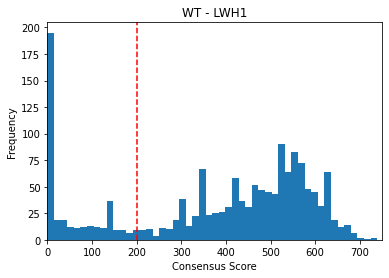

In [18]:
scores_pd = seq_df.to_pandas()

df = scores_pd[
        # (scores_pd.manual_score_growth > 2) &
        (scores_pd.db_mut_id == 0) &
        (scores_pd.ad_orf_id != aa_id) &
        (scores_pd.condition_name == 'LWH1')
        ]

df.consensus_score.plot(kind='hist', bins=50, 
                        title=f'WT - LWH1',
                        )
plt.xlim(0, 750)  # Limit y-axis to better visualize WT distribution
plt.xlabel('Consensus Score')
plt.ylabel('Frequency')
plt.axvline(x=200, color='red', linestyle='--', label='Threshold')

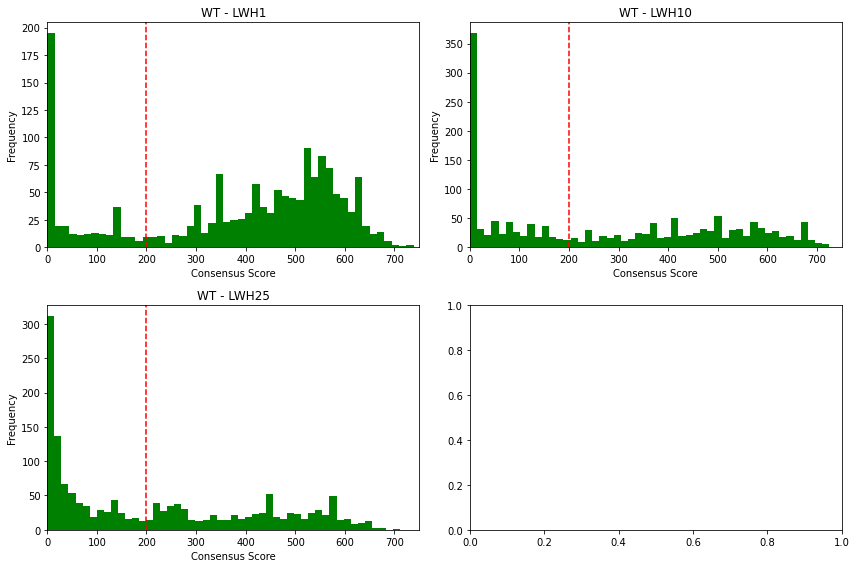

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()  # Make it easier to iterate

plot_df = scores_pd[
    (scores_pd.db_mut_id == 0) &
    (scores_pd.ad_orf_id != aa_id)
]

for i, condition in enumerate(scoring_conditions):
    df = plot_df[plot_df.condition_name == condition]
    df.consensus_score.plot(kind='hist', bins=50, 
                           title=f'WT - {condition}',
                           ax=axes[i],
                           color='green')
    axes[i].set_xlim(0, 750)  # Limit y-axis to better visualize WT distribution
    axes[i].set_xlabel('Consensus Score')
    axes[i].set_ylabel('Frequency')
    axes[i].axvline(x=200, color='red', linestyle='--', label='Threshold')

plt.tight_layout()
plt.show()

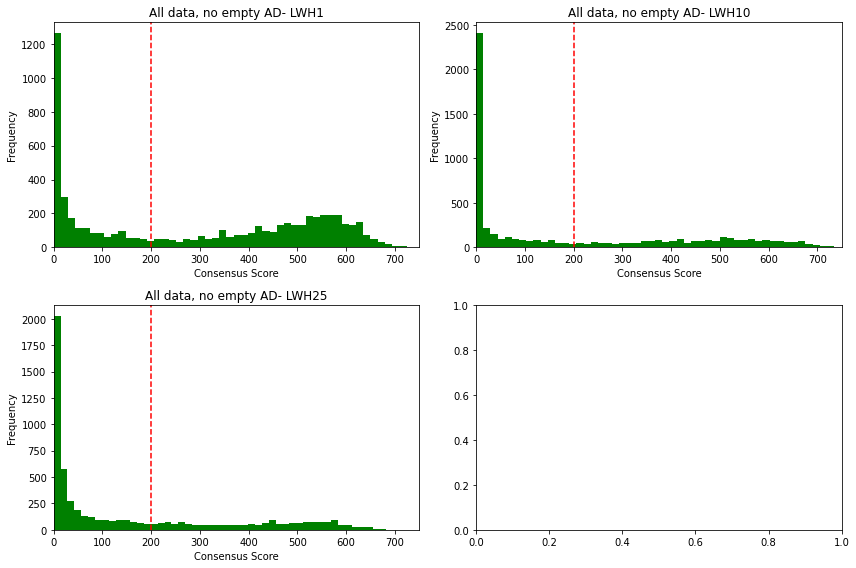

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()  # Make it easier to iterate

plot_df = scores_pd[scores_pd.ad_orf_id != aa_id].copy()

for i, condition in enumerate(scoring_conditions):
    df = plot_df[plot_df.condition_name == condition]
    df.consensus_score.plot(kind='hist', bins=50, 
                           title=f'All data, no empty AD- {condition}',
                           ax=axes[i],
                           color='green')
    axes[i].set_xlim(0, 750)  # Limit y-axis to better visualize WT distribution
    axes[i].set_xlabel('Consensus Score')
    axes[i].set_ylabel('Frequency')
    # axes[i].set_xlim(50, max_score)
    axes[i].axvline(x=200, color='red', linestyle='--', label='Threshold')
    
plt.tight_layout()
plt.show()

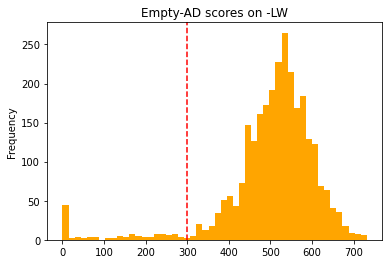

In [21]:

scores_pd[
    (scores_pd.ad_orf_id == aa_id) &
    (scores_pd.condition_name == 'LW')
].consensus_score.plot(kind='hist', bins=50, title='Empty-AD scores on -LW', color='orange')
plt.axvline(x=300, color='red', linestyle='--', label='Threshold')

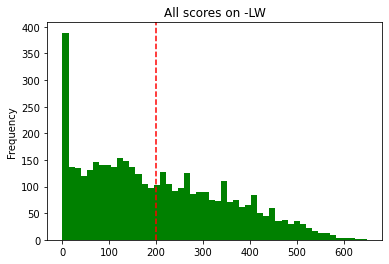

In [22]:

scores_pd[
    # (scores_pd.condition_name == 'LW') &
    (scores_pd.manual_score_growth == 2)
].consensus_score.plot(kind='hist', bins=50, title='All scores on -LW', color = 'green')
plt.axvline(x=200, color='red', linestyle='--', label='Threshold')

In [23]:
def qa_qc_filtering(df, tracking_dict=tracking_dict, min_growth_score=min_growth_score):


    scores = df


    # Remove all db groups with the same allele if there was an autoactivation mating failure
    aa_db_group_mating_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                                .filter(pl.col("condition_name") == "LW")
                                .filter(pl.col("consensus_score") <= min_growth_score)
                                .select("db_group")
                                .to_series().unique().to_list())
    scores = scores.filter(~pl.col("db_group").is_in(aa_db_group_mating_failures))


    # Remove all db-condition groups with the same allele if there was an autoactivation mating failure
    aa_db_group_tech_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                                    .filter(pl.col("consensus_score").is_nan())
                                    .select("db_condition_group")
                                    .to_series().unique().to_list())
    scores = scores.filter(~pl.col("db_condition_group").is_in(aa_db_group_tech_failures))


    tracking_dict['5. Autoactivation mating filtering'] = pull_numbers(scores, verbose=False)
    
    # Remove mating failures - condition LW with low/null consensus score
    mating_failures = (scores.filter(
                            (pl.col("condition_name") == "LW") & 
                            ((pl.col("consensus_score") <= min_growth_score) | pl.col("consensus_score").is_null())
                        )
                        .select("ppi_group")
                        .to_series()
                        .unique()
                        .to_list())
    scores = scores.filter(~pl.col("ppi_group").is_in(mating_failures))

    tracking_dict['6. Mating filtering'] = pull_numbers(scores, verbose=False)

    # Calculate aa_score per condition as the mean of the aa scores in that condition
    aa_scores = scores.filter(pl.col("ad_orf_id") == aa_id).select([
        "db_condition_group", "consensus_score"
    ]).group_by("db_condition_group").agg(
        pl.col("consensus_score").mean().alias("aa_score")  # or .first() if you want the first value
    )

    # Add the aa_score to the dataframe, merged on the condition-specific db allele
    scores = scores.filter(pl.col("ad_orf_id") != aa_id).join(aa_scores, on="db_condition_group", how="left")

    # Remove autoactivation by checking empty-AD scores
    scores = scores.filter(
        (pl.col("condition_name") == "LW") |          # keep all LW
        pl.col("aa_score").is_null() |                # or no AA score
        (pl.col("aa_score") <= min_growth_score)       # or AA score acceptable
    )
    
    # Keep only scores that aren't RRS pairs
    scores = scores.filter(pl.col('db_mut_id') != rrs_id)

    scores = scores.with_columns(
        pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
    )


    tracking_dict['7. Autoactivation filtering'] = pull_numbers(scores, verbose=False)
    

    # Remove all WT and variants from an edge if the WT failed to grow substantially in the LWH1 condition
    wt_failures = (scores.filter(pl.col("condition_name") == "LWH1")
                                .filter(pl.col("db_mut_id") == 0)
                                .filter(
                                    (pl.col("consensus_score") <= min_growth_score) | 
                                    pl.col("consensus_score").is_null()
                                )
                                .select('edge_group')
                                .to_series().unique().to_list())
    
    scores = scores.filter(~pl.col("edge_group").is_in(wt_failures))
    
        
    manual_scores = pl.read_csv(f"{outputs_dir}/3_normalized_qaqc_consensus_scores.csv")

    manual_scores = manual_scores.with_columns(
        pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
        pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id"),
        pl.col("consensus_score").alias("consensus_manual_score_growth")
    )

    # join to scores
    scores = scores.join(manual_scores.select([
        "ad_orf_id", "db_orf_id", "db_mut_id", "assay_id", "condition_name", "consensus_manual_score_growth"
    ]), on=["ad_orf_id", "db_orf_id", "db_mut_id", "assay_id", "condition_name"], how="left")

    tracking_dict['8. After WT filtering'] = pull_numbers(scores, verbose=False)


    return scores, tracking_dict

In [24]:
df, tracking_dict = qa_qc_filtering(seq_df, tracking_dict=tracking_dict)

In [25]:
def select_best_media(df, scoring_conditions=scoring_conditions, min_growth_score=min_growth_score, verbose=False, tracking_dict=tracking_dict):

    scores_pd = df.to_pandas()

    # retain only scoring conditions
    scores_pd = scores_pd[scores_pd.condition_name.isin(scoring_conditions)]

    scores_pd = scores_pd[scores_pd.consensus_score == scores_pd.consensus_score]  # remove NaNs

    # First, build WT media dict as fallback
    wt_media_dict = {} 

    for edge, df in scores_pd[scores_pd.db_mut_id == 0].groupby("edge_group"):
        for media in scoring_conditions:
            media_scores = df[df.condition_name == media]
            if not media_scores.empty and media_scores.consensus_score.values[0] >= min_growth_score:
                wt_media_dict[edge] = media

    # Now build benign media dict
    benign_media_dict = {}

    for edge, df in scores_pd[scores_pd.clinvar_clnsig_clean == "Benign"].groupby("edge_group"):
        var_dict = {}
        for ppi, ppi_df in df.groupby("ppi_group"):
            var_dict[ppi] = []
            for media in scoring_conditions:
                media_scores = ppi_df[ppi_df.condition_name == media]
                if not media_scores.empty and media_scores.consensus_score.values[0] >= min_growth_score:
                    var_dict[ppi].append(media)
                    
        if len(var_dict) == 1:
            # only one variant for this edge, take the last media where it grew
            for ppi, media_list in var_dict.items():
                if media_list:
                    benign_media_dict[edge] = media_list[-1]
        elif len(var_dict) > 1:
            # multiple benign variants. Take the last media of the most sensible variant (the one that grew in the least media)
            sorted_variants = sorted(var_dict.items(), key=lambda x: len(x[1]))
            for ppi, media_list in sorted_variants:
                if media_list:
                    benign_media_dict[edge] = media_list[-1]
                    break        

    # Combine benign and WT media dicts with benign taking priority
    combined_media_dict = {}
    for edge in set(list(benign_media_dict.keys()) + list(wt_media_dict.keys())):
        if edge in benign_media_dict:
            combined_media_dict[edge] = benign_media_dict[edge]
            # print(f"Edge {edge}: Using benign methodology -> {benign_media_dict[edge]}")
        elif edge in wt_media_dict:
            combined_media_dict[edge] = wt_media_dict[edge]
            # print(f"Edge {edge}: Fallback to WT methodology -> {wt_media_dict[edge]}")
        # If edge is in neither dict, it will be skipped
    
    if verbose:
        print(f"Total edges with benign variants: {len(benign_media_dict)}")
        print(f"Total edges with WT fallback: {len(wt_media_dict) - len(benign_media_dict)}")
        print(f"Total edges covered: {len(combined_media_dict)}")


                
    # Now filter all scores to only include the best medium per edge
    filtered_scores = []
    for edge, df in scores_pd.groupby("edge_group"):
        if edge in combined_media_dict:
            valid_media = combined_media_dict[edge]
            filtered_df = df[df.condition_name == valid_media]
            filtered_scores.append(filtered_df)
            
    if filtered_scores:
        filtered_scores = pd.concat(filtered_scores, ignore_index=True)
        if verbose:
            print(f"Filtered scores shape: {filtered_scores.shape}")
    
    # filter for edges with at least a variant and a WT
    if verbose:
        print(f"Total unique ppis before filtering: {filtered_scores['ppi_group'].nunique()}")
    valid_edges = filtered_scores.groupby("edge_group").filter(lambda x: (x.db_mut_id == 0).any() and (x.db_mut_id != 0).any())
    if verbose:
        print(f"Valid ppis after filtering: {valid_edges['ppi_group'].nunique()}")
        
    # Drop duplicates cause by different collections added in mapping
    valid_edges = valid_edges.drop_duplicates(subset=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"])
        

    valid_edges_pl = pl.from_pandas(valid_edges)

    # add wt_consensus_score column to compute log2fc

    wt_scores = valid_edges_pl.filter(pl.col("db_mut_id") == 0).select(
            [
                "edge_group", "consensus_score"
            ]
        ).rename({"consensus_score": "wt_consensus_score"})

    valid_edges_pl = valid_edges_pl.join(
        wt_scores,
        on=["edge_group"],
        how="left"
    )

    # Compute log2fc
    valid_edges_pl = valid_edges_pl.with_columns(
        np.log2(((pl.col("consensus_score") + 1) / (pl.col("wt_consensus_score") + 1)).alias("log2fc")
    ))
    
    tracking_dict['9. Best media selection'] = pull_numbers(valid_edges_pl, verbose=False)

    return valid_edges_pl, tracking_dict

In [26]:
df, tracking_dict = select_best_media(df, verbose=True, tracking_dict=tracking_dict)

Total edges with benign variants: 86
Total edges with WT fallback: 742
Total edges covered: 835
Filtered scores shape: (3042, 1043)
Total unique ppis before filtering: 2703
Valid ppis after filtering: 2133


In [27]:
def plot_patho_benign(scores=None, metric="normalized_euclid_distance_normalized", num_edge_filter=1, title=None, threshold=None, fixed_threshold=None, log_treshold=False):
    
    palette_str = "clinvar_clnsig_clean"
    
    palette_dict = {
        "clinvar_clnsig_clean":{
            'Pathogenic': "#CA7682",
            'Benign': "#1D7AAB",
            'Conflicting': "#505050", #"grey", or lighter red "#E6B1B8"
            'VUS': "#A0A0A0", ## Pillar default
            'Others': "#E0E0E0"
            # '6_No_ClinVar'
        }
    }
    

    if scores is None:
        scores = orf_distances  # This will use the current state of orf_distances
        
    print(f"Plotting {metric} distribution for Pathogenic and Benign variants")
    # total number of variants
    print("Total variants:", scores.shape[0])
    # total number of db_orf_ids
    print("Total unique db_orf_id:", scores.select(pl.col("db_orf_id").n_unique()).item())
    # total number of pathogenic variants
    print("Total Pathogenic variants:", scores.filter(pl.col("clinvar_clnsig_clean")=="Pathogenic").shape[0])
    # total number of benign variants
    print("Total Benign variants:", scores.filter(pl.col("clinvar_clnsig_clean")=="Benign").shape[0])
    
    
        
    if threshold:    
        path_thres = scores.filter(pl.col("clinvar_clnsig_clean")=="Benign")[metric].max() + 0.016
        print('path_thres:', path_thres)
        if log_treshold:
            path_thres = scores.filter(pl.col("clinvar_clnsig_clean")=="Benign")[metric].min() - 0.016
            print('path_thres:', path_thres)
        elif type(threshold) == float or type(threshold) == int:
            path_thres = threshold
            print('path_thres:', path_thres)
        
    if fixed_threshold:
        path_thres = fixed_threshold
        print('fixed_threshold:', path_thres)

    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    sns.kdeplot(data=scores.filter(pl.col("clinvar_clnsig_clean")=="Pathogenic")[metric].to_numpy(), label='Pathogenic', color=palette_dict[palette_str]["Pathogenic"], fill=True, ax=axes[0])
    sns.kdeplot(data=scores.filter(pl.col("clinvar_clnsig_clean")=="Benign")[metric].to_numpy(), label='Benign', color=palette_dict[palette_str]["Benign"], fill=True, ax=axes[0])
    if threshold:
        axes[0].axvline(x=path_thres, color=palette_dict[palette_str]["Pathogenic"], linestyle='--', label='Pathogenic Thres.')
    axes[0].legend()

    sns.histplot(scores.filter(pl.col("clinvar_clnsig_clean")=="Pathogenic")[metric].to_numpy(), label='Pathogenic', color=palette_dict[palette_str]["Pathogenic"], kde=True, ax=axes[1])
    sns.histplot(scores.filter(pl.col("clinvar_clnsig_clean")=="Benign")[metric].to_numpy(), label='Benign', color=palette_dict[palette_str]["Benign"], kde=True, ax=axes[1])
    if threshold or fixed_threshold:
        axes[1].axvline(x=path_thres, color=palette_dict[palette_str]["Pathogenic"], linestyle='--', label='Pathogenic Thres.')
    plt.subplots_adjust(hspace=.05)
    if title is not None:
        plt.suptitle(title)
    else:
        plt.suptitle(f"Distribution of {metric} scores")
    plt.show()
    
    if num_edge_filter > 1:
        benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "Benign").filter(pl.col("num_edges") >= num_edge_filter)
        # print(benign_scores.shape)

        path_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "Pathogenic").filter(pl.col("num_edges") >= num_edge_filter)
        # print(path_scores.shape)

        vus_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "VUS").filter(pl.col("num_edges") >= num_edge_filter)
        # print(vus_scores.shape)

        conf_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
        # print(conf_scores.shape)
    else:
        benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "Benign")
        path_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "Pathogenic")
        vus_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "VUS")
        conf_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "Conflicting")
    if threshold or fixed_threshold:
        if log_treshold:
            print(f"Benign: {benign_scores.filter(pl.col(metric) < path_thres).shape[0]} ({benign_scores.filter(pl.col(metric) < path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}%)")
            print(f"Pathogenic: {path_scores.filter(pl.col(metric) < path_thres).shape[0]} ({path_scores.filter(pl.col(metric) < path_thres).shape[0] / path_scores.shape[0] * 100:.2f}%)")
            print(f"VUS: {vus_scores.filter(pl.col(metric) < path_thres).shape[0]} ({vus_scores.filter(pl.col(metric) < path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}%)")
            print(f"Conflicting: {conf_scores.filter(pl.col(metric) < path_thres).shape[0]} ({conf_scores.filter(pl.col(metric) < path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}%)")
        else:
            print(f"Benign: {benign_scores.filter(pl.col(metric) > path_thres).shape[0]} ({benign_scores.filter(pl.col(metric) > path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}%)")
            print(f"Pathogenic: {path_scores.filter(pl.col(metric) > path_thres).shape[0]} ({path_scores.filter(pl.col(metric) > path_thres).shape[0] / path_scores.shape[0] * 100:.2f}%)")
            print(f"VUS: {vus_scores.filter(pl.col(metric) > path_thres).shape[0]} ({vus_scores.filter(pl.col(metric) > path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}%)")
            print(f"Conflicting: {conf_scores.filter(pl.col(metric) > path_thres).shape[0]} ({conf_scores.filter(pl.col(metric) > path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}%)")
            

In [28]:
def plot_patho_benign(scores=None, metric="normalized_euclid_distance_normalized", num_edge_filter=1, title=None, threshold=None, fixed_threshold=None, log_treshold=False, clinvar_col="clinvar_clnsig_clean"):
    """
    Plot pathogenic vs benign distribution with optional threshold.
    
    Parameters:
    -----------
    scores : pl.DataFrame, optional
        DataFrame with scores and ClinVar annotations
    metric : str
        Column name containing the metric to plot
    num_edge_filter : int
        Minimum number of edges for filtering
    title : str, optional
        Plot title
    threshold : bool or float, optional
        Whether to calculate or use a threshold
    fixed_threshold : float, optional
        Fixed threshold value to use
    log_treshold : bool
        Whether to use log-scale threshold logic
    clinvar_col : str
        Column to use for ClinVar classification ('clinvar_clnsig_clean' or 'clinvar_clnsig_clean_pp_strict')
    """
    
    # Select appropriate palette based on clinvar column
    if clinvar_col == "clinvar_clnsig_clean_pp_strict":
        palette_dict = {
            'Pathogenic': "#CA7682",
            'Likely pathogenic': "#E6B1B8",
            'Benign': "#1D7AAB",
            'Likely benign': "#7DB8D9",
            'Conflicting': "#505050",
            'VUS': "#A0A0A0",
            'Others': "#E0E0E0"
        }
        pathogenic_categories = ['Pathogenic', 'Likely pathogenic']
        benign_categories = ['Benign', 'Likely benign']
    else:
        palette_dict = {
            'Pathogenic': "#CA7682",
            'Benign': "#1D7AAB",
            'Conflicting': "#505050",
            'VUS': "#A0A0A0",
            'Others': "#E0E0E0"
        }
        pathogenic_categories = ['Pathogenic']
        benign_categories = ['Benign']
    
    if scores is None:
        scores = orf_distances  # This will use the current state of orf_distances
    
    # Filter for pathogenic and benign variants
    path_filter = pl.col(clinvar_col).is_in(pathogenic_categories)
    benign_filter = pl.col(clinvar_col).is_in(benign_categories)
    
    print(f"Plotting {metric} distribution for Pathogenic and Benign variants")
    print("Total variants:", scores.shape[0])
    print("Total unique db_orf_id:", scores.select(pl.col("db_orf_id").n_unique()).item())
    print(f"Total Pathogenic variants: {scores.filter(path_filter).shape[0]}")
    print(f"Total Benign variants: {scores.filter(benign_filter).shape[0]}")
    
    # Calculate threshold if requested
    if threshold:
        path_thres = scores.filter(benign_filter)[metric].max() + 0.016
        print('path_thres:', path_thres)
        if log_treshold:
            path_thres = scores.filter(benign_filter)[metric].min() - 0.016
            print('path_thres:', path_thres)
        elif type(threshold) == float or type(threshold) == int:
            path_thres = threshold
            print('path_thres:', path_thres)
    
    if fixed_threshold:
        path_thres = fixed_threshold
        print('fixed_threshold:', path_thres)
    
    # Create plots
    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    
    # KDE plot
    sns.kdeplot(
        data=scores.filter(path_filter)[metric].to_numpy(), 
        label='Pathogenic' if clinvar_col == "clinvar_clnsig_clean" else 'Pathogenic/Likely pathogenic',
        color=palette_dict['Pathogenic'], 
        fill=True, 
        ax=axes[0]
    )
    sns.kdeplot(
        data=scores.filter(benign_filter)[metric].to_numpy(), 
        label='Benign' if clinvar_col == "clinvar_clnsig_clean" else 'Benign/Likely benign',
        color=palette_dict['Benign'], 
        fill=True, 
        ax=axes[0]
    )
    
    if threshold or fixed_threshold:
        axes[0].axvline(x=path_thres, color=palette_dict['Pathogenic'], linestyle='--', label='Threshold')
    axes[0].legend()
    
    # Histogram plot
    sns.histplot(
        scores.filter(path_filter)[metric].to_numpy(), 
        label='Pathogenic' if clinvar_col == "clinvar_clnsig_clean" else 'Pathogenic/Likely pathogenic',
        color=palette_dict['Pathogenic'], 
        kde=True, 
        ax=axes[1]
    )
    sns.histplot(
        scores.filter(benign_filter)[metric].to_numpy(), 
        label='Benign' if clinvar_col == "clinvar_clnsig_clean" else 'Benign/Likely benign',
        color=palette_dict['Benign'], 
        kde=True, 
        ax=axes[1]
    )
    
    if threshold or fixed_threshold:
        axes[1].axvline(x=path_thres, color=palette_dict['Pathogenic'], linestyle='--', label='Threshold')
    
    plt.subplots_adjust(hspace=.05)
    if title is not None:
        plt.suptitle(title)
    else:
        plt.suptitle(f"Distribution of {metric} scores")
    plt.show()
    
    # Filter by number of edges if needed
    if num_edge_filter > 1:
        benign_scores = scores.filter(benign_filter).filter(pl.col("num_edges") >= num_edge_filter)
        path_scores = scores.filter(path_filter).filter(pl.col("num_edges") >= num_edge_filter)
        vus_scores = scores.filter(pl.col(clinvar_col) == "VUS").filter(pl.col("num_edges") >= num_edge_filter)
        conf_scores = scores.filter(pl.col(clinvar_col) == "Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
    else:
        benign_scores = scores.filter(benign_filter)
        path_scores = scores.filter(path_filter)
        vus_scores = scores.filter(pl.col(clinvar_col) == "VUS")
        conf_scores = scores.filter(pl.col(clinvar_col) == "Conflicting")
    
    # Print threshold statistics
    if threshold or fixed_threshold:
        if log_treshold:
            print(f"Benign: {benign_scores.filter(pl.col(metric) < path_thres).shape[0]} ({benign_scores.filter(pl.col(metric) < path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}%)")
            print(f"Pathogenic: {path_scores.filter(pl.col(metric) < path_thres).shape[0]} ({path_scores.filter(pl.col(metric) < path_thres).shape[0] / path_scores.shape[0] * 100:.2f}%)")
            print(f"VUS: {vus_scores.filter(pl.col(metric) < path_thres).shape[0]} ({vus_scores.filter(pl.col(metric) < path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}%)")
            print(f"Conflicting: {conf_scores.filter(pl.col(metric) < path_thres).shape[0]} ({conf_scores.filter(pl.col(metric) < path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}%)")
        else:
            print(f"Benign: {benign_scores.filter(pl.col(metric) > path_thres).shape[0]} ({benign_scores.filter(pl.col(metric) > path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}%)")
            print(f"Pathogenic: {path_scores.filter(pl.col(metric) > path_thres).shape[0]} ({path_scores.filter(pl.col(metric) > path_thres).shape[0] / path_scores.shape[0] * 100:.2f}%)")
            print(f"VUS: {vus_scores.filter(pl.col(metric) > path_thres).shape[0]} ({vus_scores.filter(pl.col(metric) > path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}%)")
            print(f"Conflicting: {conf_scores.filter(pl.col(metric) > path_thres).shape[0]} ({conf_scores.filter(pl.col(metric) > path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}%)")

Plotting log2fc distribution for Pathogenic and Benign variants
Total variants: 2133
Total unique db_orf_id: 73
Total Pathogenic variants: 899
Total Benign variants: 113


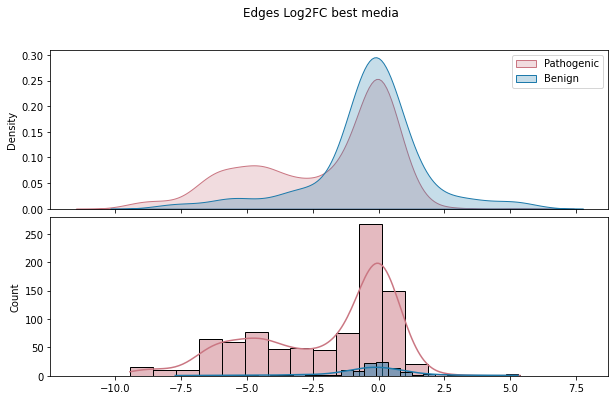

In [29]:
plot_patho_benign(scores=df, metric="log2fc", title="Edges Log2FC best media")

In [30]:
def evaluate_classification_performance(scores_df, metric_col, title=None, filter_edges=None, verbose=False, show_plots=True, balance_dataset=False):
    """
    Calculate AUROC and Precision-Recall metrics for benign vs pathogenic classification.
    
    Parameters:
    -----------
    scores_df : polars.DataFrame
        DataFrame containing scores and clinical significance
    metric_col : str
        Name of the column containing the metric to evaluate (e.g., 'log2fc')
    title : str, optional
        Title for the plots
    filter_edges : int, optional
        Minimum number of edges required to include a variant
    balance_dataset : bool, optional
        If True, balance the dataset to have equal benign and pathogenic counts (50/50 priors)
    
    Returns:
    --------
    dict : Dictionary containing AUROC, AUPRC, and other metrics
    """
    
    # Convert to pandas for sklearn compatibility
    scores_pd = scores_df.to_pandas()
    
    # Filter by number of edges if specified
    if filter_edges is not None and 'num_edges' in scores_pd.columns:
        scores_pd = scores_pd[scores_pd['num_edges'] >= filter_edges]
    
    # Filter to only benign and pathogenic
    filtered = scores_pd[scores_pd['clinvar_clnsig_clean'].isin(['Pathogenic', 'Benign'])].copy()
    
    # Remove NaN values in metric column
    filtered = filtered[filtered[metric_col].notna()]
    
    if len(filtered) < 10:
        print(f"Warning: Only {len(filtered)} variants available for evaluation")
        return None
    
    # Balance dataset if requested
    if balance_dataset:
        n_pathogenic = (filtered['clinvar_clnsig_clean'] == 'Pathogenic').sum()
        n_benign = (filtered['clinvar_clnsig_clean'] == 'Benign').sum()
        
        if n_pathogenic > n_benign:
            # Oversample benign to match pathogenic
            benign_samples = filtered[filtered['clinvar_clnsig_clean'] == 'Benign']
            pathogenic_samples = filtered[filtered['clinvar_clnsig_clean'] == 'Pathogenic']
            
            # Repeat benign samples to match pathogenic count
            n_repeats = n_pathogenic // n_benign
            n_remainder = n_pathogenic % n_benign
            
            balanced_benign = pd.concat([benign_samples] * n_repeats + 
                                       [benign_samples.sample(n=n_remainder, random_state=42)], 
                                       ignore_index=True)
            filtered = pd.concat([pathogenic_samples, balanced_benign], ignore_index=True)
            
        elif n_benign > n_pathogenic:
            # Oversample pathogenic to match benign
            benign_samples = filtered[filtered['clinvar_clnsig_clean'] == 'Benign']
            pathogenic_samples = filtered[filtered['clinvar_clnsig_clean'] == 'Pathogenic']
            
            # Repeat pathogenic samples to match benign count
            n_repeats = n_benign // n_pathogenic
            n_remainder = n_benign % n_pathogenic
            
            balanced_pathogenic = pd.concat([pathogenic_samples] * n_repeats + 
                                           [pathogenic_samples.sample(n=n_remainder, random_state=42)], 
                                           ignore_index=True)
            filtered = pd.concat([benign_samples, balanced_pathogenic], ignore_index=True)
        
        if verbose:
            print(f"Dataset balanced: {(filtered['clinvar_clnsig_clean'] == 'Pathogenic').sum()} pathogenic, "
                  f"{(filtered['clinvar_clnsig_clean'] == 'Benign').sum()} benign")
    
    # Create binary labels (1 = Pathogenic, 0 = Benign)
    y_true = (filtered['clinvar_clnsig_clean'] == 'Pathogenic').astype(int)
    y_scores = filtered[metric_col].values
    
    # For log2fc, more negative = more pathogenic, so we negate for ROC
    # Adjust this based on your metric interpretation
    y_scores_roc = -y_scores  # Negative log2fc indicates loss of function (pathogenic)
    
    # Calculate ROC curve and AUROC
    fpr, tpr, roc_thresholds = roc_curve(y_true, y_scores_roc)
    roc_auc = auc(fpr, tpr)
    
    # Calculate Precision-Recall curve and AUPRC
    precision, recall, pr_thresholds = precision_recall_curve(y_true, y_scores_roc)
    auprc = average_precision_score(y_true, y_scores_roc)
    
    # Calculate optimal threshold (Youden's index for ROC)
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold_roc = -roc_thresholds[optimal_idx]  # Convert back to original scale
    
    if show_plots:    
        # Create plots
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
        # ROC Curve
        axes[0].plot(fpr, tpr, color='royalblue', lw=2, 
                    label=f'ROC curve (AUC = {roc_auc:.3f})')
        axes[0].plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--', label='Random')
        axes[0].set_xlim([0.0, 1.0])
        axes[0].set_ylim([0.0, 1.05])
        axes[0].set_xlabel('False Positive Rate')
        axes[0].set_ylabel('True Positive Rate')
        axes[0].set_title('ROC Curve')
        axes[0].legend(loc="lower right")
        axes[0].grid(alpha=0.3)
        
        # Precision-Recall Curve
        axes[1].plot(recall, precision, color='royalblue', lw=2,
                    label=f'PR curve (AP = {auprc:.3f})')
        axes[1].axhline(y=y_true.mean(), color='grey', linestyle='--', lw=2,
                        label=f'Random (prevalence = {y_true.mean():.3f})')
        axes[1].set_xlim([0.0, 1.0])
        # axes[1].set_ylim([0.0, 1.05])
        axes[1].set_xlabel('Recall (Sensitivity)')
        axes[1].set_ylabel('Precision (PPV)')
        axes[1].set_title('Precision-Recall Curve')
        axes[1].legend(loc="lower left")
        axes[1].grid(alpha=0.3)
        
        if title:
            fig.suptitle(title, fontsize=14, y=1.02)
        
        plt.tight_layout()
        plt.show()
    
    # Calculate additional metrics at optimal threshold
    y_pred_optimal = (y_scores_roc >= roc_thresholds[optimal_idx]).astype(int)
    
    tp = np.sum((y_pred_optimal == 1) & (y_true == 1))
    fp = np.sum((y_pred_optimal == 1) & (y_true == 0))
    tn = np.sum((y_pred_optimal == 0) & (y_true == 0))
    fn = np.sum((y_pred_optimal == 0) & (y_true == 1))
    
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    ppv = tp / (tp + fp) if (tp + fp) > 0 else 0
    npv = tn / (tn + fn) if (tn + fn) > 0 else 0
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    # Print summary
    if verbose:
        print(f"\n{'='*60}")
        print(f"Classification Performance: {title if title else metric_col}")
        print(f"{'='*60}")
        print(f"Dataset: {len(filtered)} variants ({y_true.sum()} pathogenic, {len(y_true) - y_true.sum()} benign)")
        print(f"\nArea Under ROC Curve (AUROC): {roc_auc:.4f}")
        print(f"Area Under PR Curve (AUPRC):  {auprc:.4f}")
        print(f"\nOptimal Threshold (Youden): {optimal_threshold_roc:.4f}")
        print(f"\nPerformance at Optimal Threshold:")
        print(f"  Sensitivity (Recall):  {sensitivity:.4f}")
        print(f"  Specificity:           {specificity:.4f}")
        print(f"  Precision (PPV):       {ppv:.4f}")
        print(f"  Negative Pred. Value:  {npv:.4f}")
        print(f"  Accuracy:              {accuracy:.4f}")
        print(f"{'='*60}\n")
    
    # Return metrics dictionary
    return {
        'auroc': roc_auc,
        'auprc': auprc,
        'optimal_threshold': optimal_threshold_roc,
        'sensitivity': sensitivity,
        'specificity': specificity,
        'precision': ppv,
        'npv': npv,
        'accuracy': accuracy,
        'n_variants': len(filtered),
        'n_pathogenic': y_true.sum(),
        'n_benign': len(y_true) - y_true.sum(),
        'fpr': fpr,
        'tpr': tpr,
        'roc_thresholds': roc_thresholds,
        'precision_curve': precision,
        'recall_curve': recall,
        'pr_thresholds': pr_thresholds
    }

Dataset balanced: 899 pathogenic, 899 benign


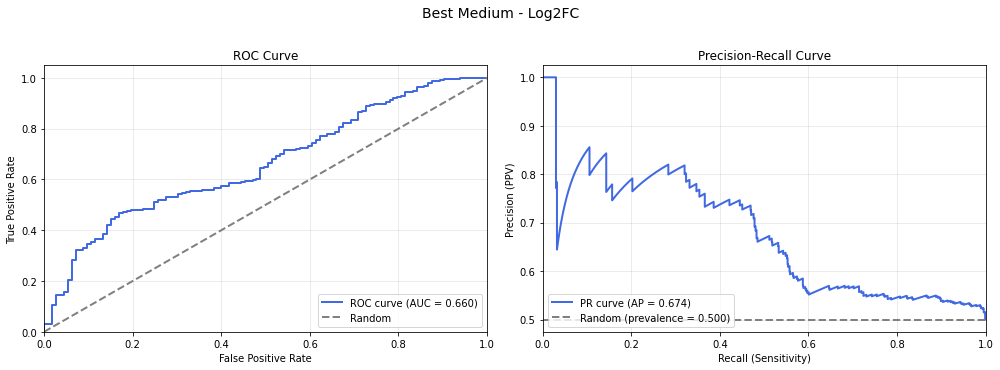


Classification Performance: Best Medium - Log2FC
Dataset: 1798 variants (899 pathogenic, 899 benign)

Area Under ROC Curve (AUROC): 0.6599
Area Under PR Curve (AUPRC):  0.6740

Optimal Threshold (Youden): -1.1623

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.4694
  Specificity:           0.8309
  Precision (PPV):       0.7352
  Negative Pred. Value:  0.6103
  Accuracy:              0.6502



In [31]:
perf = evaluate_classification_performance(
    df.filter(pl.col("db_mut_id") != 0),
    metric_col='log2fc',
    title='Best Medium - Log2FC',
    verbose=True,
    balance_dataset=True
)

In [32]:
df

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,contamination,outlier_score,outlier_size_score,size_score_raw,size_score,consensus_score,ad_symbol,symbol,ensembl_gene_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,seq,seq_aa,collection,…,g2p_Repeat (UniProt),g2p_SNP-associated PTMs,g2p_SUMOylation,g2p_Secondary structure (DSSP 3-state)*,g2p_Secondary structure (DSSP 9-state)*,g2p_Secondary structure (PDBe/SIFTS),g2p_Sequence conflict (UniProt),g2p_Sequence uncertainty (UniProt),g2p_Signal (UniProt),g2p_Site (UniProt),g2p_Substrate genes,g2p_Topological domain (UniProt),g2p_Transit peptide (UniProt),g2p_Transmembrane (UniProt),g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final_right,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,i64,i64,bool,bool,bool,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,…,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,f64,str,str,str,str,str,str,str,str,f64,f64,f64,f64
"""VUSAPWT6B1r05_010""","""A01""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""","""6""",false,100000046,null,7323,216370,"""VUSMutY8Dh020""","""B07""","""CEGSint_Y8A6_1""","""H03""",616.734667,3.0,1115,1,false,false,false,687659.15331,638.495036,626.486022,"""CLDN5""","""PMP22""","""ENSG00000109099""","""CCSBVarC006152""","""ALE00006152""","""NC_000017.11:15230952:C:A""","""448G>T""","""Gly150Cys""","""ATGCTCCTCCTGTTGCTGAGTATCATCGTC…","""MLLLLLSIIVLHVAVLVLLFVSTIVSQWIV…","""CEGS2""",…,null,"""dbSNP: rs104894624; Variant ty…",null,"""H (helix)""","""H (α-helix)""",null,null,null,null,null,null,null,null,"""Helical""",null,null,96.78,0.0,""">90""","""<10""",null,null,null,"""Genetic otorhinolaryngologic d…",3.0,null,"""7323.0_216370.0_VUSAPWT6B1""","""7323.0_216370.0_LWH25_VUSAPWT6…","""100000046.0_7323.0_216370.0_VU…","""100000046.0_7323.0_VUSAPWT6B1""","""1""","""1""","""Y""",12.196559,3.0,503.182724,0.315637
"""VUSAPWT6B1r05_010""","""E01""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""","""6""",false,100000046,null,7323,216371,"""VUSMutY8Dh020""","""H06""","""CEGSint_Y8A6_1""","""H03""",546.500673,3.0,1078,1,false,false,false,589127.725747,547.008102,298.82591,"""CLDN5""","""PMP22""","""ENSG00000109099""","""CCSBVarC006153""","""ALE00006153""","""NC_000017.11:15230931:G:A""","""469C>T""","""Arg157Trp""","""ATGCTCCTCCTGTTGCTGAGTATCATCGTC…","""MLLLLLSIIVLHVAVLVLLFVSTIVSQWIV…","""CEGS2""",…,null,"""dbSNP: rs28936682; Variant typ…",null,"""B (undefined)""","""B (beta bridge)""",null,null,null,null,null,null,"""Cytoplasmic""",null,null,null,null,86.92,60.080647,"""70-90""","""10-90""","""162500;118300""","""autosomal dominant""","""OMIM""","""Genetic otorhinolaryngologic d…",3.0,"""NEUROPATHY, HEREDITARY, WITH L…","""7323.0_216371.0_VUSAPWT6B1""","""7323.0_216371.0_LWH25_VUSAPWT6…","""100000046.0_7323.0_216371.0_VU…","""100000046.0_7323.0_VUSAPWT6B1""","""1""","""1""","""Y""",71.332251,3.0,503.182724,-0.749822
"""VUSAPWT6B1r05_009""","""K23""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""","""6""",false,100000046,null,7323,0,"""DisWTY8Dh02""","""D09""","""CEGSint_Y8A6_1""","""H03""",0.0,3.0,0,0,false,false,false,0.0,0.0,503.182724,"""CLDN5""",null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,""

In [33]:
def compute_orf_distances(df):
    
    # normalize consensus score based on max score
    
    consensus_max = df.select(pl.col("consensus_score").max()).item()
    
    df = df.with_columns(
        (pl.col("consensus_score") / consensus_max).alias("consensus_score_normalized"),
        (pl.col("wt_consensus_score") / consensus_max).alias("wt_consensus_score_normalized"),
    )
    
    # Create profiles for each profiled gene
    
    genes = df.select("db_orf_id").to_series().unique().to_list()
    profiles = dict()
    shape_summary = []
    
    for gene in genes:
        gene_scores = df.filter(pl.col("db_orf_id") == gene)
        profile = gene_scores.pivot(
                    values="consensus_score_normalized",
                    index="ad_orf_id",
                    on="db_mut_id"
                )
        
        profiles[gene] = profile

        shape_summary.append({
            "gene": gene,
            "n_interactors": profile.height,
            "n_alleles": profile.width
        })

    shape_summary = pl.DataFrame(shape_summary)
        
    zero_col = "0"

    orf_distances = []


    for orf, profile in profiles.items():
            
        columns = [col for col in profile.columns if col != "ad_orf_id"]

        # "impute" missing values as the mean for that variant
        profile_filled = profile.with_columns([
            pl.when(pl.col(col).is_null())
            .then(pl.col(col).mean())
            .otherwise(pl.col(col))
            .alias(col)
            for col in columns
        ])
        
        # compute distances
        distance_rows = []
        for col in columns:
            if col == zero_col:
                continue
            
            # Euclidean distance
            diff_squared = (profile_filled[col] - profile_filled[zero_col]) ** 2
            distances = np.sqrt(diff_squared.sum())
            

            distance_rows.append({
                "db_orf_id": orf,
                "db_mut_id": int(col),
                "euclid_distance": distances,
                "num_edges": profile.shape[0],
            })


        result_profile = pl.DataFrame(distance_rows)
        orf_distances.append(result_profile)

    # concatentate and normalize wrt dimensionality
    orf_distances = pl.concat(orf_distances, how="vertical_relaxed")
    orf_distances = orf_distances.with_columns(
        (pl.col("euclid_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_euclid_distance"),
        pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
        pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
    )

    orf_distances = orf_distances.with_columns(
        (pl.col("normalized_euclid_distance") / pl.col("normalized_euclid_distance").max()).alias("normalized_euclid_distance_normalized"),
    )
    
    orf_distances = metadata_mapping(orf_distances, inputs_dir=inputs_dir, map_ad_symbol=False)
    
    orf_distances = orf_distances.unique(subset=["db_orf_id", "db_mut_id"])
    
    # cast db_orf_id and db_mut_id back to Int64
    orf_distances = orf_distances.with_columns(
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    )
    
    # Drop alleles that were tested multiple times, keep only one (the one with the highest db_mut_id, which should be the most recent)
    orf_distances = orf_distances.sort("db_mut_id", descending=True).unique(subset=["gene_variant"], keep="first")
    
    return orf_distances

In [34]:
orf_distances = compute_orf_distances(df)
orf_distances

db_orf_id,db_mut_id,euclid_distance,num_edges,normalized_euclid_distance,normalized_euclid_distance_normalized,symbol,ensembl_gene_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,seq,seq_aa,collection,entry_plate_orig,entry_well_orig,entry_plate_conso,entry_well_conso,entry_seq_pool,db_plate,db_well,n2h_plate,n2h_well,dualip_plate,dualip_well,mislocalization_plate,mislocalization_well,entry_sequenced,entry_sequence_confirmation_class,db_sequenced,db_sequence_confirmation_class,n2h_sequenced,n2h_sequence_confirmation_class,n2h_ref_sequence_confirmation_class,dualip_sequenced,…,g2p_Non-terminal residue (UniProt),g2p_O-GalNAc,g2p_O-GlcNAc,g2p_Peptide (UniProt),g2p_Phi angle (degrees)*,g2p_Phosphorylation,g2p_Pocket number (fpocket)*,g2p_Propeptide (UniProt),g2p_Psi angle (degrees)*,g2p_Region (UniProt),g2p_Regulatory sites,g2p_Repeat (UniProt),g2p_SNP-associated PTMs,g2p_SUMOylation,g2p_Secondary structure (DSSP 3-state)*,g2p_Secondary structure (DSSP 9-state)*,g2p_Secondary structure (PDBe/SIFTS),g2p_Sequence conflict (UniProt),g2p_Sequence uncertainty (UniProt),g2p_Signal (UniProt),g2p_Site (UniProt),g2p_Substrate genes,g2p_Topological domain (UniProt),g2p_Transit peptide (UniProt),g2p_Transmembrane (UniProt),g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names
i64,i64,f64,i64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,…,str,str,str,str,f64,str,str,str,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,i64,str
55855,219422,0.925366,3,0.534261,0.577692,"""KRT2""","""ENSG00000172867""","""CCSBVarC003452""","""ALE00003452""","""NC_000012.12:52646782:T:A""","""1427A>T""","""Glu476Val""","""ATGAGTTGTCAGATCTCTTGCAAATCTCGA…","""MSCQISCKSRGRGGGGGGFRGFSSGSAVVS…","""CEGS2""","""CegsMutGDEh1037""","""D09""","""GDEhDisVCh_40073""","""G07""","""1""","""CegsMutGDDh1037""","""D09""","""VUSN2Hmut_GDN2h_07""","""B09""","""VUSMutpDEST2_13""","""A07""","""VUSmut_GDEh07""","""B09""",1.0,1.0,1.0,1.0,1.0,1.0,6.0,1.0,…,null,null,null,null,-60.8,null,null,null,-44.2,"""Coil 2""",null,null,null,null,"""H (helix)""","""H (α-helix)""",null,null,null,null,null,null,null,null,null,null,null,93.5,47.938145,""">90""","""10-90""",null,null,null,"""Rare genetic skin disease""",1,null
70497,3867,0.501581,1,0.501581,0.542355,"""AGXT""","""ENSG00000172482""","""CCSBVarC008219""","""ALE00008205""","""NC_000002.12:240875997:C:T""","""839C>T""","""Ala280Val""","""ATGGCCTCTCACAAGCTGCTGGTGACCCCC…","""MASHKLLVTPPKALLKPLSIPNQLLLGPGP…","""Edgotyping3""","""VUSMutGDEh004""","""F08""","""GDEhDisVCh_40002""","""D10""","""2""","""VUSMutGDDh004""","""F08""","""VUSN2Hmut_GDN2h_01""","""C09""","""VUSMutpDEST2_14""","""H09""","""VUSmut_GDEh01""","""C09""",1.0,3.0,1.0,1.0,1.0,1.0,1.0,1.0,…,null,null,null,null,-68.4,null,null,null,-41.4,null,null,null,"""dbSNP: rs73106685; Variant typ…",null,"""H (helix)""","""H (α-helix)""","""Helix""",null,null,null,null,null,null,null,null,null,null,98.87,49.056606,""">90""","""10-90""","""259900""","""autosomal recessive""","""OMIM""","""Rare genetic eye disease; Rare…",3,"""HYPEROXALURIA, PRIMARY, TYPE I"""
71337,3941,0.984829,3,0.568591,0.614814,"""ACSF3""","""ENSG00000176715""","""CCSBVarC008269""","""ALE00008255""","""NC_000016.10:89101037:G:A""","""356G>A""","""Gly119Asp""","""ATGCCGCCCCATGTGGTGCTCACCTTCCGG…","""MPPHVVLTFRRLGCALASCRLAPARHRGSG…","""Edgotyping3""","""VUSMutGDEh009""","""C06""","""GDEhDisVCh_40021""","""H10""","""1""","""VUSMutGDDh009""","""C06""","""VUSN2Hmut_GDN2h_03""","""G01""","""VUSMutpDEST2_15""","""D04""","""VUSmut_GDEh03""","""G01""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,…,null,null,null,null,71.7,null,null,null,16.0,null,null,null,null,null,"""C (loop/coil)""","""T (turn)""",null,null,null,null,null,null,null,null,null,null,nu

Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 511
Total unique db_orf_id: 73
Total Pathogenic variants: 259
Total Benign variants: 31


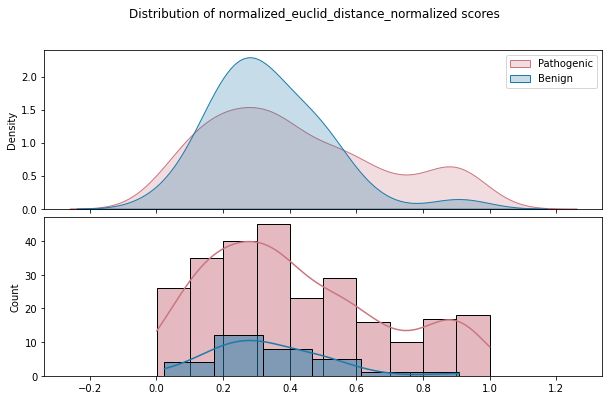

In [35]:
plot_patho_benign(scores=orf_distances)#, threshold=LLR_threshold)

# Run full pipeline to get final scores

In [36]:
min_growth_score = 200
scoring_conditions = ['LWH1', 'LWH10', 'LWH25', 'LWA']

def run_full_pipeline(min_growth_score=min_growth_score, scoring_conditions=scoring_conditions, use_median=False):
    """
    Run the complete sqY2H analysis pipeline.
    
    Parameters:
    -----------
    min_growth_score : int
        Minimum growth score threshold for filtering
    scoring_conditions : list
        List of scoring conditions to use for best media selection
        
    Returns:
    --------
    tuple : (df, orf_distances, perf, tracking_dict)
        - df: Polars DataFrame with filtered edge-level scores
        - orf_distances: Polars DataFrame with variant-level distance metrics
        - perf: Dictionary with classification performance metrics
        - tracking_dict: Dictionary tracking data at each pipeline step
    """
    # Initialize tracking
    tracking_dict = {}
    
    # Load original dataframe
    df, tracking_dict = load_original_dataframe(
        file_path=original_datafile_path,
        tracking_dict=tracking_dict
    )
    
    # Initial QA/QC
    df, tracking_dict = initial_qaqc(df, tracking_dict=tracking_dict)
    
    # Calculate consensus scores
    df, tracking_dict = consensus_score_calculation(df, tracking_dict=tracking_dict, use_median=use_median)
    
    # Map metadata
    df = metadata_mapping(df, meta_output=meta_output, inputs_dir=inputs_dir)
    
    # Sequencing filtering
    df, tracking_dict = sequencing_filtering(
        df,
        tracking_dict=tracking_dict,
        meta_output=meta_output,
        inputs_dir=inputs_dir
    )
    
    # QA/QC filtering
    df, tracking_dict = qa_qc_filtering(
        df,
        tracking_dict=tracking_dict,
        min_growth_score=min_growth_score
    )
    
    # Select best media
    df, tracking_dict = select_best_media(
        df,
        scoring_conditions=scoring_conditions,
        min_growth_score=min_growth_score,
        verbose=True,
        tracking_dict=tracking_dict
    )
    
    # Evaluate classification performance
    perf = evaluate_classification_performance(
        df.filter(pl.col("db_mut_id") != 0),
        metric_col='log2fc',
        title='PPIs - Log2FC',
        verbose=True,
        balance_dataset=True
    )
    
    # Compute ORF distances
    orf_distances = compute_orf_distances(df)
    
    # Plot distribution
    plot_patho_benign(
        scores=orf_distances,
        metric="normalized_euclid_distance_normalized",
        title="ORF Distances - Normalized Euclidean Distance"
    )
    
    # Evaluate classification performance
    perf = evaluate_classification_performance(
        orf_distances.filter(pl.col("db_mut_id") != 0),
        metric_col='normalized_euclid_distance_normalized',
        title='ORF Distances - Normalized Euclidean Distance',
        verbose=True,
        balance_dataset=True
    )
    
    return df, orf_distances, perf, tracking_dict

## No LWA

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Total edges with benign variants: 88
Total edges with WT fallback: 792
Total edges covered: 886
Filtered scores shape: (3226, 1043)
Total unique ppis before filtering: 2884
Valid ppis after filtering: 2284
Dataset balanced: 972 pathogenic, 972 benign


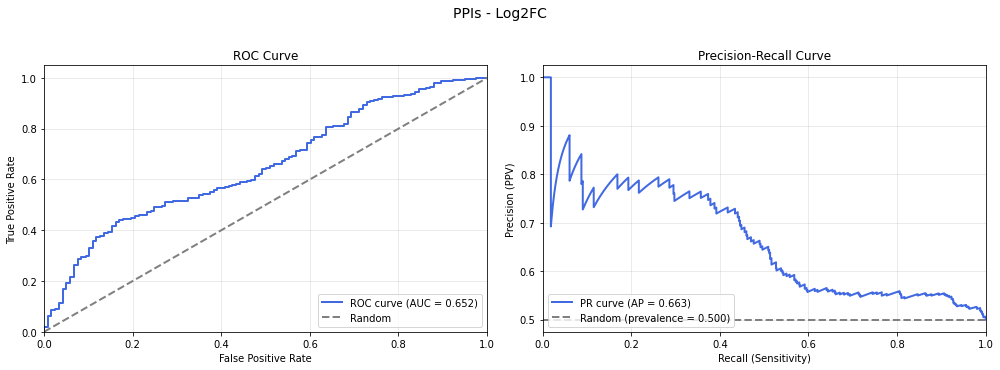


Classification Performance: PPIs - Log2FC
Dataset: 1944 variants (972 pathogenic, 972 benign)

Area Under ROC Curve (AUROC): 0.6523
Area Under PR Curve (AUPRC):  0.6628

Optimal Threshold (Youden): -1.1961

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.4342
  Specificity:           0.8385
  Precision (PPV):       0.7288
  Negative Pred. Value:  0.5971
  Accuracy:              0.6363

Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 523
Total unique db_orf_id: 75
Total Pathogenic variants: 268
Total Benign variants: 31


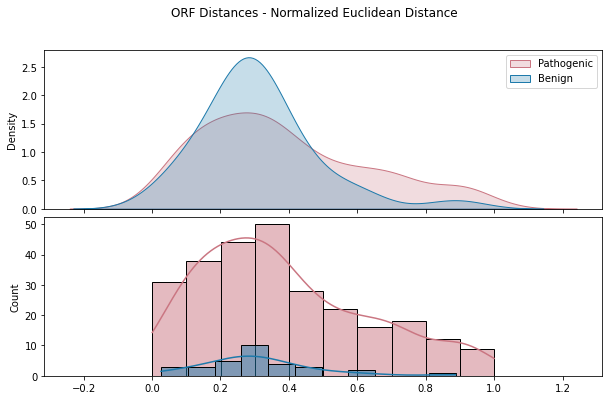

Dataset balanced: 268 pathogenic, 268 benign


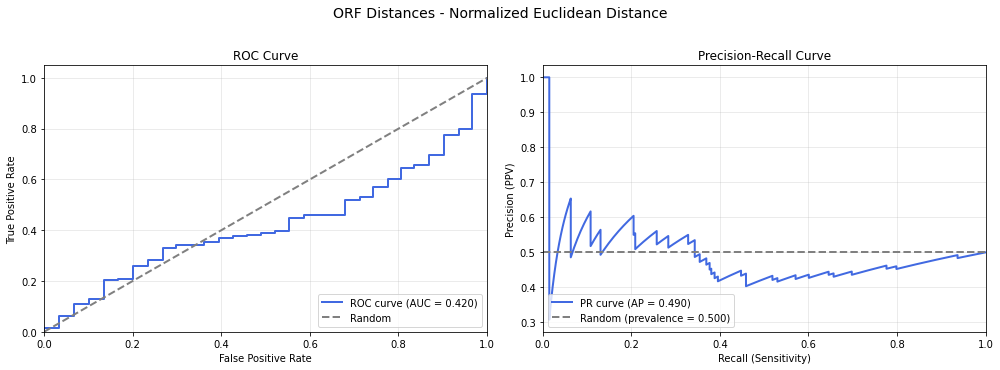


Classification Performance: ORF Distances - Normalized Euclidean Distance
Dataset: 536 variants (268 pathogenic, 268 benign)

Area Under ROC Curve (AUROC): 0.4204
Area Under PR Curve (AUPRC):  0.4903

Optimal Threshold (Youden): 0.1649

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.2052
  Specificity:           0.8657
  Precision (PPV):       0.6044
  Negative Pred. Value:  0.5213
  Accuracy:              0.5354



In [37]:
min_growth_score = 200
scoring_conditions = ['LWH1', 'LWH10', 'LWH25']

df, orf_distances, perf, tracking_dict = run_full_pipeline(min_growth_score=min_growth_score, scoring_conditions=scoring_conditions)

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Total edges with benign variants: 86
Total edges with WT fallback: 742
Total edges covered: 835
Filtered scores shape: (3042, 1043)
Total unique ppis before filtering: 2703
Valid ppis after filtering: 2133
Dataset balanced: 899 pathogenic, 899 benign


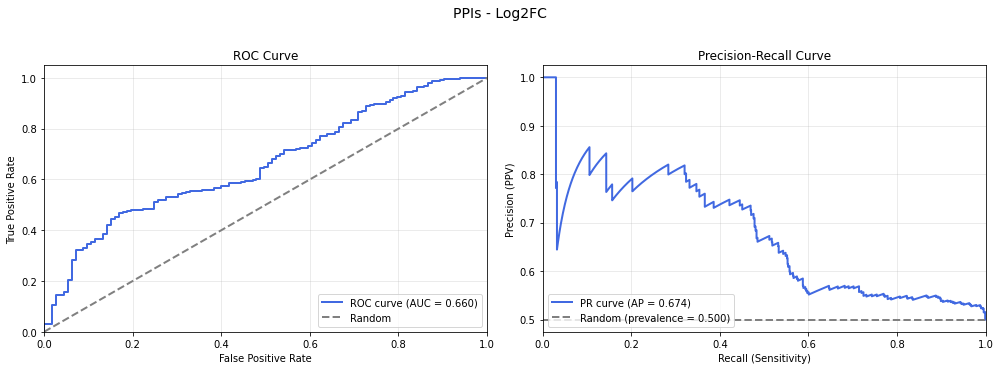


Classification Performance: PPIs - Log2FC
Dataset: 1798 variants (899 pathogenic, 899 benign)

Area Under ROC Curve (AUROC): 0.6599
Area Under PR Curve (AUPRC):  0.6740

Optimal Threshold (Youden): -1.1623

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.4694
  Specificity:           0.8309
  Precision (PPV):       0.7352
  Negative Pred. Value:  0.6103
  Accuracy:              0.6502

Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 511
Total unique db_orf_id: 73
Total Pathogenic variants: 259
Total Benign variants: 31


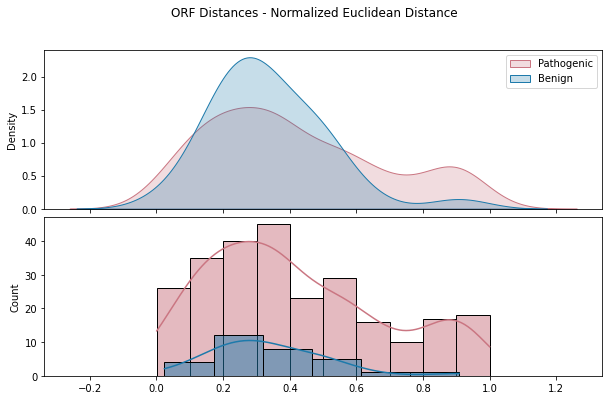

Dataset balanced: 259 pathogenic, 259 benign


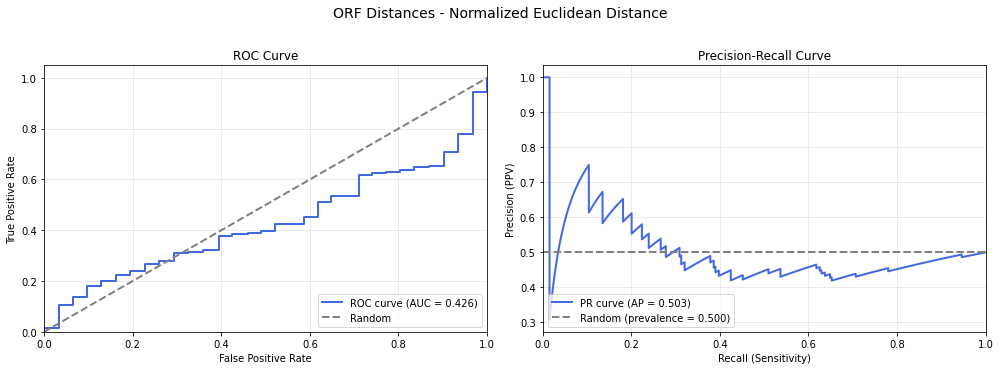


Classification Performance: ORF Distances - Normalized Euclidean Distance
Dataset: 518 variants (259 pathogenic, 259 benign)

Area Under ROC Curve (AUROC): 0.4262
Area Under PR Curve (AUPRC):  0.5028

Optimal Threshold (Youden): 0.1554

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.1815
  Specificity:           0.9035
  Precision (PPV):       0.6528
  Negative Pred. Value:  0.5247
  Accuracy:              0.5425



In [38]:
min_growth_score = 200
scoring_conditions = ['LWH1', 'LWH10', 'LWH25']

df, orf_distances, perf, tracking_dict = run_full_pipeline(min_growth_score=min_growth_score, scoring_conditions=scoring_conditions, use_median=True)

In [71]:
orf_distances.write_csv(f"{outputs_dir}/orf_distances_final.csv")

In [39]:
# Get unique symbols from df and save to CSV
unique_symbols = df.select(pl.col("symbol")).unique().sort("symbol")
unique_symbols.write_csv("./tmp/unique_symbols.csv")
print(f"Saved {unique_symbols.shape[0]} unique symbols to unique_symbols.csv")


Saved 74 unique symbols to unique_symbols.csv


In [40]:
old_orfs = pd.read_csv("./tmp/unique_orfs.csv")
old_orfs

,db_orf_id
0,143
1,145
2,281
3,386
4,513
...,...
70,71077
71,71191
72,71337
73,71892


In [41]:
current_orfs = df.select(pl.col("db_orf_id")).unique().sort("db_orf_id")
current_orfs

db_orf_id
i64
143
145
281
386
513
…
71077
71191
71337


In [42]:
# compare old and current orfs

# Compare old and current orfs
old_orfs_set = set(old_orfs['db_orf_id'].values)
current_orfs_set = set(current_orfs['db_orf_id'].to_list())

# ORFs in old but not in current (lost ORFs)
lost_orfs = old_orfs_set - current_orfs_set
print(f"ORFs lost (in old but not current): {len(lost_orfs)}")
if lost_orfs:
    print("Lost ORF IDs:", sorted(lost_orfs))

# ORFs in current but not in old (gained ORFs)
gained_orfs = current_orfs_set - old_orfs_set
print(f"\nORFs gained (in current but not old): {len(gained_orfs)}")
if gained_orfs:
    print("Gained ORF IDs:", sorted(gained_orfs))

# ORFs in both (retained ORFs)
retained_orfs = old_orfs_set & current_orfs_set
print(f"\nORFs retained (in both): {len(retained_orfs)}")

# Summary
print(f"\n{'='*60}")
print("Summary:")
print(f"  Old dataset:      {len(old_orfs_set)} ORFs")
print(f"  Current dataset:  {len(current_orfs_set)} ORFs")
print(f"  Retained:         {len(retained_orfs)} ORFs")
print(f"  Lost:             {len(lost_orfs)} ORFs")
print(f"  Gained:           {len(gained_orfs)} ORFs")
print(f"{'='*60}")

# Optional: Create a comparison DataFrame
comparison_df = pd.DataFrame({
    'db_orf_id': sorted(old_orfs_set | current_orfs_set),
})
comparison_df['in_old'] = comparison_df['db_orf_id'].isin(old_orfs_set)
comparison_df['in_current'] = comparison_df['db_orf_id'].isin(current_orfs_set)
comparison_df['status'] = comparison_df.apply(
    lambda row: 'Retained' if (row['in_old'] and row['in_current'])
    else 'Lost' if row['in_old']
    else 'Gained',
    axis=1
)

print("\nComparison table:")
print(comparison_df.value_counts('status'))

# Show the comparison table
comparison_df

ORFs lost (in old but not current): 3
Lost ORF IDs: [1256, 3449, 7651]

ORFs gained (in current but not old): 1
Gained ORF IDs: [7465]

ORFs retained (in both): 72

Summary:
  Old dataset:      75 ORFs
  Current dataset:  73 ORFs
  Retained:         72 ORFs
  Lost:             3 ORFs
  Gained:           1 ORFs

Comparison table:
status
Retained    72
Lost         3
Gained       1
Name: count, dtype: int64


,db_orf_id,in_old,in_current,status
0,143,True,True,Retained
1,145,True,True,Retained
2,281,True,True,Retained
3,386,True,True,Retained
4,513,True,True,Retained
...,...,...,...,...
71,71077,True,True,Retained
72,71191,True,True,Retained
73,71337,True,True,Retained
74,71892,True,True,Retained


In [43]:
# number of ppi_group, edge_group, db_orf_id, db_mut_id in df

print("Final filtered dataframe stats:")
print("Number of unique ppi_group:", df.select(pl.col("ppi_group").n_unique()).item())
print("Number of unique edge_group:", df.select(pl.col("edge_group").n_unique()).item())
print("Number of unique db_orf_id:", df.select(pl.col("db_orf_id").n_unique()).item())
print("Number of unique db_mut_id:", df.select(pl.col("gene_variant").n_unique()).item() - 1)

Final filtered dataframe stats:
Number of unique ppi_group: 2133
Number of unique edge_group: 291
Number of unique db_orf_id: 73
Number of unique db_mut_id: 511


In [44]:
# number of ppi_group, edge_group, db_orf_id, db_mut_id in df

print("Final filtered dataframe stats:")
print("Number of unique ppi_group:", df.select(pl.col("ppi_group").n_unique()).item())
print("Number of unique edge_group:", df.select(pl.col("edge_group").n_unique()).item())
print("Number of unique db_orf_id:", df.select(pl.col("db_orf_id").n_unique()).item())
print("Number of unique db_mut_id:", df.select(pl.col("gene_variant").n_unique()).item() - 1)

Final filtered dataframe stats:
Number of unique ppi_group: 2133
Number of unique edge_group: 291
Number of unique db_orf_id: 73
Number of unique db_mut_id: 511


In [45]:
def add_structural_categories(orf_distances):
    """
    Add pLDDT and RSA category columns to orf_distances DataFrame.
    
    Parameters:
    -----------
    orf_distances : pl.DataFrame
        DataFrame containing plddt and rsa columns
        
    Returns:
    --------
    pl.DataFrame
        DataFrame with added pLDDT_Category and RSA_Category columns
    """
    
    # Define RSA categories
    orf_distances = orf_distances.with_columns(
        pl.when(pl.col("rsa") < 0.10)
        .then(pl.lit("<10"))
        .when((pl.col("rsa") >= 0.10) & (pl.col("rsa") < 0.90))
        .then(pl.lit("10-90"))
        .when(pl.col("rsa") >= 0.90)
        .then(pl.lit("≥90"))
        .otherwise(None)
        .alias("RSA_Category")
    )
    
    # Define pLDDT categories
    orf_distances = orf_distances.with_columns(
        pl.when(pl.col("plddt") <= 50)
        .then(pl.lit("<=50"))
        .when((pl.col("plddt") > 50) & (pl.col("plddt") <= 70))
        .then(pl.lit("50-70"))
        .when((pl.col("plddt") > 70) & (pl.col("plddt") <= 90))
        .then(pl.lit("70-90"))
        .when(pl.col("plddt") > 90)
        .then(pl.lit(">90"))
        .otherwise(None)
        .alias("pLDDT_Category")
    )
    
    return orf_distances

In [46]:
# Add categories to orf_distances
orf_distances = add_structural_categories(orf_distances)

# Check the result
print(orf_distances.select(['plddt', 'pLDDT_Category', 'rsa', 'RSA_Category']).head())

# Check distribution
print("\nRSA Category counts:")
print(orf_distances.group_by('RSA_Category').agg(pl.count()).sort('RSA_Category'))

print("\npLDDT Category counts:")
print(orf_distances.group_by('pLDDT_Category').agg(pl.count()).sort('pLDDT_Category'))

shape: (5, 4)
┌───────┬────────────────┬──────────┬──────────────┐
│ plddt ┆ pLDDT_Category ┆ rsa      ┆ RSA_Category │
│ ---   ┆ ---            ┆ ---      ┆ ---          │
│ f64   ┆ str            ┆ f64      ┆ str          │
╞═══════╪════════════════╪══════════╪══════════════╡
│ 27.55 ┆ <=50           ┆ 0.857143 ┆ 10-90        │
│ 83.26 ┆ 70-90          ┆ 0.573248 ┆ 10-90        │
│ 97.52 ┆ >90            ┆ 0.675258 ┆ 10-90        │
│ 98.56 ┆ >90            ┆ 0.059524 ┆ <10          │
│ 79.84 ┆ 70-90          ┆ 0.785366 ┆ 10-90        │
└───────┴────────────────┴──────────┴──────────────┘

RSA Category counts:
shape: (4, 2)
┌──────────────┬───────┐
│ RSA_Category ┆ count │
│ ---          ┆ ---   │
│ str          ┆ u32   │
╞══════════════╪═══════╡
│ null         ┆ 7     │
│ 10-90        ┆ 315   │
│ <10          ┆ 165   │
│ ≥90          ┆ 24    │
└──────────────┴───────┘

pLDDT Category counts:
shape: (5, 2)
┌────────────────┬───────┐
│ pLDDT_Category ┆ count │
│ ---            ┆ ---   

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_9355/3766873533.py:9: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  print(orf_distances.group_by('RSA_Category').agg(pl.count()).sort('RSA_Category'))
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_9355/3766873533.py:12: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  print(orf_distances.group_by('pLDDT_Category').agg(pl.count()).sort('pLDDT_Category'))


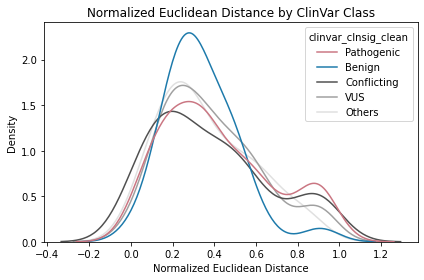

In [47]:
variables = ["normalized_euclid_distance_normalized"]


# Only plot the first variable
var = variables[0]
hue_order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

sns.kdeplot(
    data=orf_distances,
    x=var,
    hue="clinvar_clnsig_clean",
    hue_order=hue_order,
    # palette=[color_map.get(k, "gray") for k in hue_order],
    palette=palette_dict['clinvar_clnsig_clean'],
    common_norm=False
)

threshold = 0.42

# plt.axvline(x=threshold, color='red', linestyle='--', label='Threshold')

plt.title('Normalized Euclidean Distance by ClinVar Class')
plt.xlabel('Normalized Euclidean Distance')
plt.tight_layout()
plt.show()

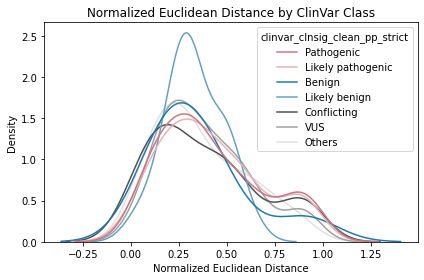

In [48]:
variables = ["normalized_euclid_distance_normalized"]


# Only plot the first variable
var = variables[0]
hue_order = ["Pathogenic", 'Likely pathogenic', "Benign", 'Likely benign', "Conflicting", "VUS", "Others"]

sns.kdeplot(
    data=orf_distances,
    x=var,
    hue="clinvar_clnsig_clean_pp_strict",
    hue_order=hue_order,
    # palette=[color_map.get(k, "gray") for k in hue_order],
    palette=palette_dict['clinvar_clnsig_clean_pp_strict'],
    common_norm=False
)

threshold = 0.42

# plt.axvline(x=threshold, color='red', linestyle='--', label='Threshold')

plt.title('Normalized Euclidean Distance by ClinVar Class')
plt.xlabel('Normalized Euclidean Distance')
plt.tight_layout()
plt.show()

In [49]:
orf_distances.to_pandas().db_mut_id.nunique()

511

In [50]:
orf_distances.to_pandas().clinvar_clnsig_clean.value_counts()

clinvar_clnsig_clean
Pathogenic     259
VUS             92
Conflicting     80
Others          49
Benign          31
Name: count, dtype: int64

In [51]:
orf_distances.to_pandas().clinvar_clnsig_clean_pp_strict.value_counts()

clinvar_clnsig_clean_pp_strict
Pathogenic           159
Likely pathogenic     95
VUS                   92
Conflicting           79
Others                55
Likely benign         23
Benign                 8
Name: count, dtype: int64

## LWA

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Total edges with benign variants: 89
Total edges with WT fallback: 792
Total edges covered: 887
Filtered scores shape: (3259, 1043)
Total unique ppis before filtering: 2916
Valid ppis after filtering: 2326
Dataset balanced: 991 pathogenic, 991 benign


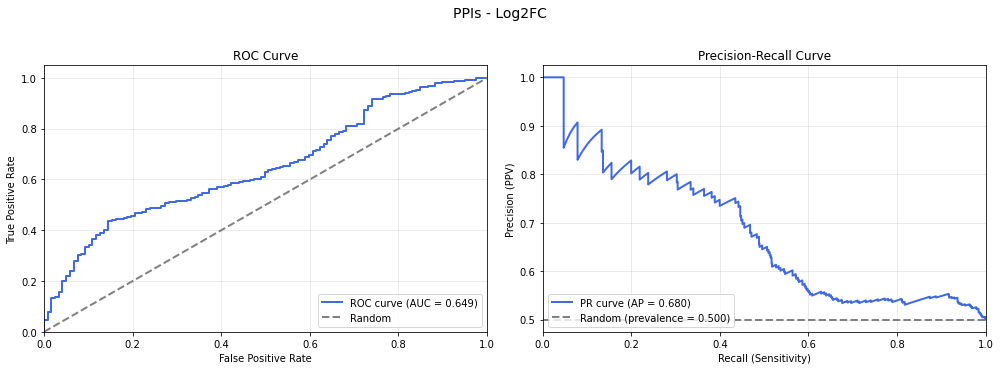


Classification Performance: PPIs - Log2FC
Dataset: 1982 variants (991 pathogenic, 991 benign)

Area Under ROC Curve (AUROC): 0.6495
Area Under PR Curve (AUPRC):  0.6798

Optimal Threshold (Youden): -1.1961

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.4349
  Specificity:           0.8557
  Precision (PPV):       0.7509
  Negative Pred. Value:  0.6023
  Accuracy:              0.6453

Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 524
Total unique db_orf_id: 75
Total Pathogenic variants: 268
Total Benign variants: 31


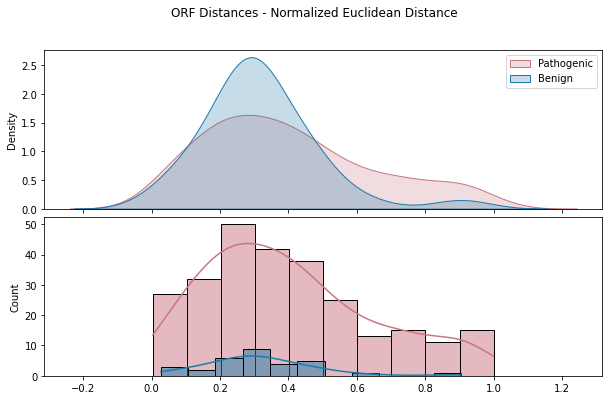

Dataset balanced: 268 pathogenic, 268 benign


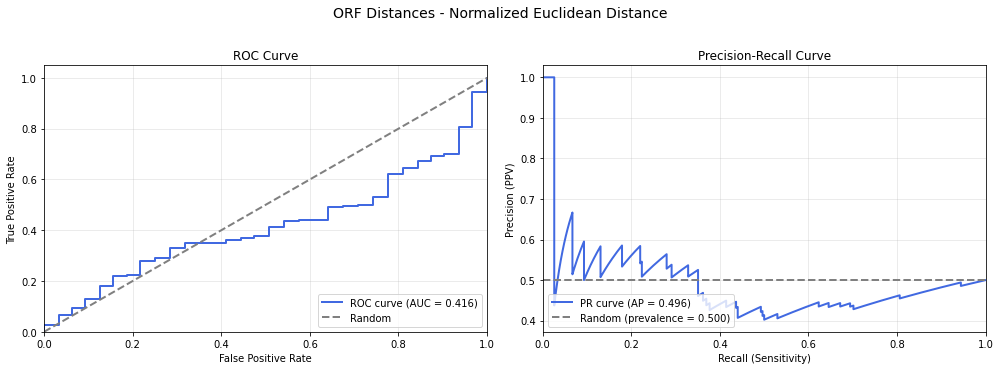


Classification Performance: ORF Distances - Normalized Euclidean Distance
Dataset: 536 variants (268 pathogenic, 268 benign)

Area Under ROC Curve (AUROC): 0.4160
Area Under PR Curve (AUPRC):  0.4956

Optimal Threshold (Youden): 0.2025

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.2201
  Specificity:           0.8433
  Precision (PPV):       0.5842
  Negative Pred. Value:  0.5195
  Accuracy:              0.5317



In [52]:
min_growth_score = 200
scoring_conditions = ['LWH1', 'LWH10', 'LWH25', 'LWA']

df_lwa, orf_distances_lwa, perf_lwa, tracking_dict_lwa = run_full_pipeline(min_growth_score=min_growth_score, scoring_conditions=scoring_conditions)

In [53]:
# number of ppi_group, edge_group, db_orf_id, db_mut_id in df_lwa

print("Final filtered dataframe stats:")
print("Number of unique ppi_group:", df_lwa.select(pl.col("ppi_group").n_unique()).item())
print("Number of unique edge_group:", df_lwa.select(pl.col("edge_group").n_unique()).item())
print("Number of unique db_orf_id:", df_lwa.select(pl.col("db_orf_id").n_unique()).item())
print("Number of unique db_mut_id:", df_lwa.select(pl.col("gene_variant").n_unique()).item() - 1)

Final filtered dataframe stats:
Number of unique ppi_group: 2326
Number of unique edge_group: 317
Number of unique db_orf_id: 75
Number of unique db_mut_id: 524


## AUROC comparison between LWA and non-LWA

In [54]:
def compare_classification_performance(scores_df1, scores_df2, metric_col, 
                                      label1='Dataset 1', label2='Dataset 2',
                                      title=None, filter_edges=None, 
                                      verbose=False, balance_dataset=False):
    """
    Compare classification performance between two datasets on the same ROC and PR plots.
    
    Parameters:
    -----------
    scores_df1 : polars.DataFrame
        First DataFrame containing scores and clinical significance
    scores_df2 : polars.DataFrame
        Second DataFrame containing scores and clinical significance
    metric_col : str
        Name of the column containing the metric to evaluate (e.g., 'log2fc')
    label1 : str
        Label for first dataset
    label2 : str
        Label for second dataset
    title : str, optional
        Title for the plots
    filter_edges : int, optional
        Minimum number of edges required to include a variant
    balance_dataset : bool, optional
        If True, balance the datasets to have equal benign and pathogenic counts
    
    Returns:
    --------
    dict : Dictionary containing metrics for both datasets
    """
    
    def prepare_data(scores_df, balance=False):
        """Helper function to prepare data for each dataset"""
        scores_pd = scores_df.to_pandas()
        
        # Filter by number of edges if specified
        if filter_edges is not None and 'num_edges' in scores_pd.columns:
            scores_pd = scores_pd[scores_pd['num_edges'] >= filter_edges]
        
        # Filter to only benign and pathogenic
        filtered = scores_pd[scores_pd['clinvar_clnsig_clean'].isin(['Pathogenic', 'Benign'])].copy()
        
        # Remove NaN values in metric column
        filtered = filtered[filtered[metric_col].notna()]
        
        if len(filtered) < 10:
            print(f"Warning: Only {len(filtered)} variants available")
            return None, None, None
        
        # Balance dataset if requested
        if balance:
            n_pathogenic = (filtered['clinvar_clnsig_clean'] == 'Pathogenic').sum()
            n_benign = (filtered['clinvar_clnsig_clean'] == 'Benign').sum()
            
            if n_pathogenic > n_benign:
                benign_samples = filtered[filtered['clinvar_clnsig_clean'] == 'Benign']
                pathogenic_samples = filtered[filtered['clinvar_clnsig_clean'] == 'Pathogenic']
                
                n_repeats = n_pathogenic // n_benign
                n_remainder = n_pathogenic % n_benign
                
                balanced_benign = pd.concat([benign_samples] * n_repeats + 
                                           [benign_samples.sample(n=n_remainder, random_state=42)], 
                                           ignore_index=True)
                filtered = pd.concat([pathogenic_samples, balanced_benign], ignore_index=True)
                
            elif n_benign > n_pathogenic:
                benign_samples = filtered[filtered['clinvar_clnsig_clean'] == 'Benign']
                pathogenic_samples = filtered[filtered['clinvar_clnsig_clean'] == 'Pathogenic']
                
                n_repeats = n_benign // n_pathogenic
                n_remainder = n_benign % n_pathogenic
                
                balanced_pathogenic = pd.concat([pathogenic_samples] * n_repeats + 
                                               [pathogenic_samples.sample(n=n_remainder, random_state=42)], 
                                               ignore_index=True)
                filtered = pd.concat([benign_samples, balanced_pathogenic], ignore_index=True)
        
        # Create binary labels (1 = Pathogenic, 0 = Benign)
        y_true = (filtered['clinvar_clnsig_clean'] == 'Pathogenic').astype(int)
        y_scores = filtered[metric_col].values
        
        # For log2fc, more negative = more pathogenic, so we negate for ROC
        y_scores_roc = -y_scores
        
        return y_true, y_scores_roc, filtered
    
    # Prepare data for both datasets
    y_true1, y_scores1, filtered1 = prepare_data(scores_df1, balance=balance_dataset)
    y_true2, y_scores2, filtered2 = prepare_data(scores_df2, balance=balance_dataset)
    
    if y_true1 is None or y_true2 is None:
        return None
    
    # Calculate metrics for both datasets
    fpr1, tpr1, roc_thresholds1 = roc_curve(y_true1, y_scores1)
    roc_auc1 = auc(fpr1, tpr1)
    precision1, recall1, pr_thresholds1 = precision_recall_curve(y_true1, y_scores1)
    auprc1 = average_precision_score(y_true1, y_scores1)
    
    fpr2, tpr2, roc_thresholds2 = roc_curve(y_true2, y_scores2)
    roc_auc2 = auc(fpr2, tpr2)
    precision2, recall2, pr_thresholds2 = precision_recall_curve(y_true2, y_scores2)
    auprc2 = average_precision_score(y_true2, y_scores2)
    
    # Create comparison plots
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # ROC Curve
    axes[0].plot(fpr1, tpr1, color='royalblue', lw=2, 
                label=f'{label1} (AUC = {roc_auc1:.3f})')
    axes[0].plot(fpr2, tpr2, color='coral', lw=2, 
                label=f'{label2} (AUC = {roc_auc2:.3f})')
    axes[0].plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--', label='Random')
    axes[0].set_xlim([0.0, 1.0])
    axes[0].set_ylim([0.0, 1.05])
    axes[0].set_xlabel('False Positive Rate')
    axes[0].set_ylabel('True Positive Rate')
    axes[0].set_title('ROC Curve Comparison')
    axes[0].legend(loc="lower right")
    axes[0].grid(alpha=0.3)
    
    # Precision-Recall Curve
    axes[1].plot(recall1, precision1, color='royalblue', lw=2,
                label=f'{label1} (AP = {auprc1:.3f})')
    axes[1].plot(recall2, precision2, color='coral', lw=2,
                label=f'{label2} (AP = {auprc2:.3f})')
    axes[1].axhline(y=y_true1.mean(), color='grey', linestyle='--', lw=2,
                    label=f'Random (prevalence = {y_true1.mean():.3f})')
    axes[1].set_xlim([0.0, 1.0])
    axes[1].set_xlabel('Recall (Sensitivity)')
    axes[1].set_ylabel('Precision (PPV)')
    axes[1].set_title('Precision-Recall Curve Comparison')
    axes[1].legend(loc="lower left")
    axes[1].grid(alpha=0.3)
    
    if title:
        fig.suptitle(title, fontsize=14, y=1.02)
    
    plt.tight_layout()
    plt.show()
    
    # Print comparison summary
    if verbose:
        print(f"\n{'='*80}")
        print(f"Classification Performance Comparison: {title if title else metric_col}")
        print(f"{'='*80}")
        print(f"\n{label1}:")
        print(f"  Dataset: {len(filtered1)} variants ({y_true1.sum()} pathogenic, {len(y_true1) - y_true1.sum()} benign)")
        print(f"  AUROC: {roc_auc1:.4f}")
        print(f"  AUPRC: {auprc1:.4f}")
        
        print(f"\n{label2}:")
        print(f"  Dataset: {len(filtered2)} variants ({y_true2.sum()} pathogenic, {len(y_true2) - y_true2.sum()} benign)")
        print(f"  AUROC: {roc_auc2:.4f}")
        print(f"  AUPRC: {auprc2:.4f}")
        
        print(f"\nDifference:")
        print(f"  ΔAUROC: {roc_auc2 - roc_auc1:+.4f}")
        print(f"  ΔAUPRC: {auprc2 - auprc1:+.4f}")
        print(f"{'='*80}\n")
    
    # Return metrics for both datasets
    return {
        'dataset1': {
            'label': label1,
            'auroc': roc_auc1,
            'auprc': auprc1,
            'n_variants': len(filtered1),
            'n_pathogenic': y_true1.sum(),
            'n_benign': len(y_true1) - y_true1.sum(),
            'fpr': fpr1,
            'tpr': tpr1,
            'precision': precision1,
            'recall': recall1
        },
        'dataset2': {
            'label': label2,
            'auroc': roc_auc2,
            'auprc': auprc2,
            'n_variants': len(filtered2),
            'n_pathogenic': y_true2.sum(),
            'n_benign': len(y_true2) - y_true2.sum(),
            'fpr': fpr2,
            'tpr': tpr2,
            'precision': precision2,
            'recall': recall2
        }
    }

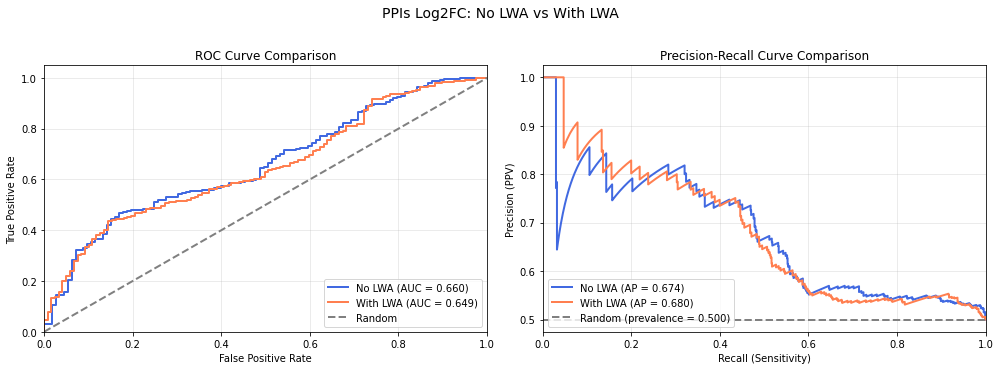


Classification Performance Comparison: PPIs Log2FC: No LWA vs With LWA

No LWA:
  Dataset: 1798 variants (899 pathogenic, 899 benign)
  AUROC: 0.6599
  AUPRC: 0.6740

With LWA:
  Dataset: 1982 variants (991 pathogenic, 991 benign)
  AUROC: 0.6495
  AUPRC: 0.6798

Difference:
  ΔAUROC: -0.0104
  ΔAUPRC: +0.0059



In [55]:
# Compare df and df_lwa
comparison = compare_classification_performance(
    df.filter(pl.col("db_mut_id") != 0),
    df_lwa.filter(pl.col("db_mut_id") != 0),
    metric_col='log2fc',
    label1='No LWA',
    label2='With LWA',
    title='PPIs Log2FC: No LWA vs With LWA',
    verbose=True,
    balance_dataset=True
)

# LLR

## no LWA

In [56]:
orf_distances.to_pandas().clinvar_clnsig_clean_pp_strict.value_counts()

clinvar_clnsig_clean_pp_strict
Pathogenic           159
Likely pathogenic     95
VUS                   92
Conflicting           79
Others                55
Likely benign         23
Benign                 8
Name: count, dtype: int64

In [57]:
orf_distances.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Benign", "Likely pathogenic", "Likely benign"])
).with_columns(
    pl.when(
        pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
    )
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("normalized_euclid_distance_normalized").alias("score"),
    pl.col("gene_variant").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "normalized_euclid_distance_normalized", "gene_variant", "clinvar_clnsig_clean_pp_strict"])
).write_csv("../3_outputs/sqY2H/PPI_Best_Media_referenceSet.csv")

orf_distances.with_columns(
    pl.col("normalized_euclid_distance_normalized").alias("score"),
    pl.col("gene_variant").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/PPI_Best_Media_allScores.csv")

In [58]:
orf_distances.to_pandas().db_orf_id.nunique()

73

In [59]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_bcv.log" --bandwidth "bcv" --printTransitions  --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_default.log" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_nrd.log" --bandwidth "nrd" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_sj.log" --printTransitions --bandwidth "SJ" --kernel "gaussian" --outlierSuppression 0.1

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-14_12:40:29 INFO: Reading input 
2025-11-14_12:40:29 INFO: Calculating densties 


Warning message:
In stats::bw.bcv(data) : minimum occurred at one end of the range


2025-11-14_12:40:30 INFO: Drawing LLR plot 
2025-11-14_12:40:30 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-14_12:40:30 INFO: Category transitions:  
0.678 : none -> patho.support
0.762 : patho.support -> patho.moderate
0.928 : patho.moderate -> patho.support
2025-11-14_12:40:30 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-14_12:40:30 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_score_bcv.csv 
2025-11-14_12:40:30 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


...

2025-11-14_12:40:34 INFO: Drawing LLR plot 
2025-11-14_12:40:34 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-14_12:40:34 INFO: Category transitions:  
0.700 : none -> patho.support
0.837 : patho.support -> patho.moderate
0.957 : patho.moderate -> patho.support
0.992 : patho.support -> none
2025-11-14_12:40:34 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-14_12:40:34 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_score_default.csv 
2025-11-14_12:40:34 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-14_12:40:35 INFO: Reading input 
2025-11-14_12:40:35 INFO: Calculating densties 
2025-11-14_12:40:36 INFO: Drawing LLR plot 
2025-11-14_12:40:36 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-14_12:40:36 INFO: Category transitions:  
0.669 : none -> patho.support
0.743 : patho.support -> patho.moderate
0.901 : patho.moderate -> patho.support
2025-11-14_12:40:36 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-14_12:40:36 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_score_nrd.csv 
2025-11-14_12:40:36 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-14_12:40:37 INFO: Reading input 
2025-11-14_12:40:37 INFO: Calculating densties 
2025-11-14_12:40:38 INFO: Drawing LLR plot 
2025-11-14_12:40:38 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-14_12:40:39 INFO: Category transitions:  
0.669 : none -> patho.support
0.747 : patho.support -> patho.moderate
0.955 : patho.moderate -> patho.support
2025-11-14_12:40:39 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-14_12:40:39 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_score_sj.csv 
2025-11-14_12:40:39 INFO: Done! 


In [60]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_bcv.log" --bandwidth "bcv" --printTransitions  --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_default.log" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_nrd.log" --bandwidth "nrd" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_sj.log" --printTransitions --bandwidth "SJ" --kernel "gaussian" --outlierSuppression 0.1

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-14_12:40:41 INFO: Reading input 
2025-11-14_12:40:41 INFO: Calculating densties 


Warning message:
In stats::bw.bcv(data) : minimum occurred at one end of the range


2025-11-14_12:40:42 INFO: Drawing LLR plot 
2025-11-14_12:40:42 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-14_12:40:43 INFO: Category transitions:  
0.678 : none -> patho.support
0.762 : patho.support -> patho.moderate
0.928 : patho.moderate -> patho.support
2025-11-14_12:40:43 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-14_12:40:43 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_score_bcv.csv 
2025-11-14_12:40:43 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


...

2025-11-14_12:40:46 INFO: Drawing LLR plot 
2025-11-14_12:40:46 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-14_12:40:47 INFO: Category transitions:  
0.700 : none -> patho.support
0.837 : patho.support -> patho.moderate
0.957 : patho.moderate -> patho.support
0.992 : patho.support -> none
2025-11-14_12:40:47 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-14_12:40:47 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_score_default.csv 
2025-11-14_12:40:47 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-14_12:40:48 INFO: Reading input 
2025-11-14_12:40:48 INFO: Calculating densties 
2025-11-14_12:40:49 INFO: Drawing LLR plot 
2025-11-14_12:40:49 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-14_12:40:49 INFO: Category transitions:  
0.669 : none -> patho.support
0.743 : patho.support -> patho.moderate
0.901 : patho.moderate -> patho.support
2025-11-14_12:40:49 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-14_12:40:49 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_score_nrd.csv 
2025-11-14_12:40:49 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-14_12:40:50 INFO: Reading input 
2025-11-14_12:40:50 INFO: Calculating densties 
2025-11-14_12:40:51 INFO: Drawing LLR plot 
2025-11-14_12:40:51 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-14_12:40:51 INFO: Category transitions:  
0.669 : none -> patho.support
0.747 : patho.support -> patho.moderate
0.955 : patho.moderate -> patho.support
2025-11-14_12:40:51 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-14_12:40:51 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LLR_score_sj.csv 
2025-11-14_12:40:51 INFO: Done! 


In [61]:
LLR_threshold = 0.678

In [62]:
orf_distances = orf_distances.with_columns(
    pl.when(pl.col("normalized_euclid_distance_normalized") >= LLR_threshold)
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("ppi_hit")
)

In [ ]:
orf_distances.write_csv(f"{outputs_dir}/orf_distances_final.csv")

Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 511
Total unique db_orf_id: 73
Total Pathogenic variants: 259
Total Benign variants: 31
path_thres: 0.9241599048743057
fixed_threshold: 0.62


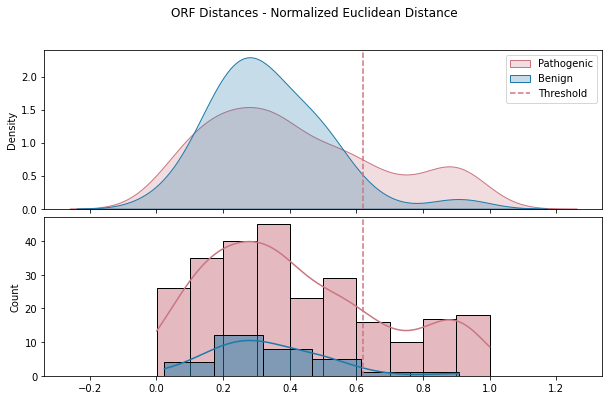

Benign: 2 (6.45%)
Pathogenic: 57 (22.01%)
VUS: 14 (15.22%)
Conflicting: 15 (18.75%)


In [63]:
plot_patho_benign(orf_distances, metric="normalized_euclid_distance_normalized", threshold=True, fixed_threshold=0.620, title="ORF Distances - Normalized Euclidean Distance")

Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 511
Total unique db_orf_id: 73
Total Pathogenic variants: 254
Total Benign variants: 31
path_thres: 0.9241599048743057
fixed_threshold: 0.62


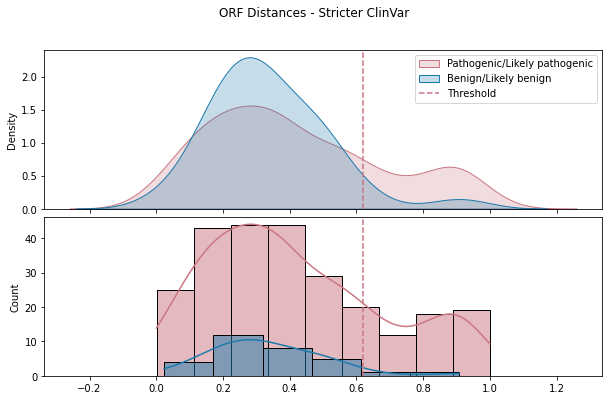

Benign: 2 (6.45%)
Pathogenic: 55 (21.65%)
VUS: 14 (15.22%)
Conflicting: 15 (18.99%)


In [64]:
# Using the stricter classification (including Likely pathogenic/benign)
plot_patho_benign(
    orf_distances, 
    metric="normalized_euclid_distance_normalized", 
    threshold=True, 
    fixed_threshold=0.620, 
    title="ORF Distances - Stricter ClinVar",
    clinvar_col="clinvar_clnsig_clean_pp_strict"
)

## LWA

In [65]:
orf_distances_lwa.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Benign", "Likely pathogenic", "Likely benign"])
).with_columns(
    pl.when(
        pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
    )
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("normalized_euclid_distance_normalized").alias("score"),
    pl.col("gene_variant").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "normalized_euclid_distance_normalized", "gene_variant", "clinvar_clnsig_clean_pp_strict"])
).write_csv("../3_outputs/sqY2H/PPI_Best_Media_LWA_referenceSet.csv")

orf_distances_lwa.with_columns(
    pl.col("normalized_euclid_distance_normalized").alias("score"),
    pl.col("gene_variant").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/PPI_Best_Media_LWA_allScores.csv")

In [66]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_LWA_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_LWA_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LWA_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LWA_LLR_bcv.log" --bandwidth "bcv" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_LWA_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_LWA_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LWA_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LWA_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_LWA_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_LWA_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LWA_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LWA_LLR_default.log" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_LWA_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_LWA_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LWA_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LWA_LLR_nrd.log" --bandwidth "nrd" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_LWA_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_LWA_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LWA_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LWA_LLR_sj.log" --printTransitions --bandwidth "SJ"

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-14_12:40:55 INFO: Reading input 
2025-11-14_12:40:56 INFO: Calculating densties 


Warning message:
In stats::bw.bcv(data) : minimum occurred at one end of the range


2025-11-14_12:40:57 INFO: Drawing LLR plot 
2025-11-14_12:40:57 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-14_12:40:57 INFO: Category transitions:  
0.632 : none -> patho.support
0.677 : patho.support -> patho.moderate
0.742 : patho.moderate -> patho.support
0.781 : patho.support -> patho.moderate
0.876 : patho.moderate -> patho.support
2025-11-14_12:40:57 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-14_12:40:57 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LWA_LLR_score_bcv.csv 
2025-11-14_12:40:57 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


...

2025-11-14_12:41:01 INFO: Reading input 
2025-11-14_12:41:01 INFO: Calculating densties 


Error in value[[3L]](cond) : 
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>


2025-11-14_12:41:02 FATAL: Error in value[[3L]](cond) : 
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>
 
  


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-14_12:41:03 INFO: Reading input 
2025-11-14_12:41:03 INFO: Calculating densties 
2025-11-14_12:41:04 INFO: Drawing LLR plot 
2025-11-14_12:41:04 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-14_12:41:05 INFO: Category transitions:  
0.551 : none -> patho.support
0.679 : patho.support -> patho.moderate
0.707 : patho.moderate -> patho.strong
0.713 : patho.strong -> patho.vstrong
0.808 : patho.vstrong -> patho.strong
0.814 : patho.strong -> patho.moderate
0.835 : patho.moderate -> patho.support
0.878 : patho.support -> none
0.959 : none -> patho.support
0.989 : patho.support -> patho.moderate
1.000 : patho.moderate -> patho.strong
2025-11-14_12:41:05 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-14_12:41:05 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_Best_Media_LWA_LLR_score_sj.csv 
2025-11-14_12:41:05 INFO: Done! 


Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 524
Total unique db_orf_id: 75
Total Pathogenic variants: 268
Total Benign variants: 31
path_thres: 0.9210531520151957
fixed_threshold: 0.629


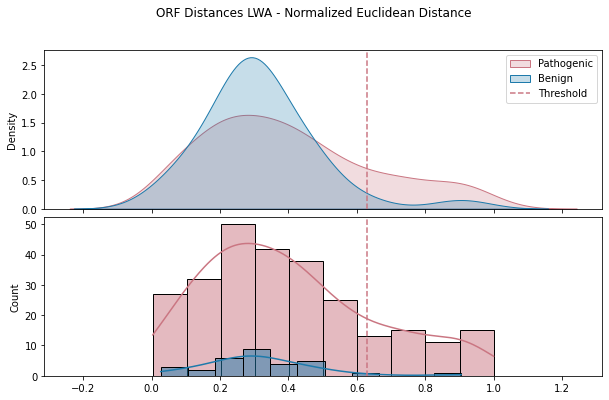

Benign: 1 (3.23%)
Pathogenic: 50 (18.66%)
VUS: 15 (16.13%)
Conflicting: 16 (19.28%)


In [67]:
plot_patho_benign(orf_distances_lwa, metric="normalized_euclid_distance_normalized", threshold=True, fixed_threshold=0.629, title="ORF Distances LWA - Normalized Euclidean Distance")

## Edge level

In [68]:
df.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Benign", "Likely pathogenic", "Likely benign"])
).with_columns(
    pl.when(
        pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
    )
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("log2fc").alias("score"),
    pl.col("ppi_group").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "log2fc", "ppi_group", "clinvar_clnsig_clean_pp_strict"])
).write_csv("../3_outputs/sqY2H/PPI_Best_Media_Edges_referenceSet.csv")

df.with_columns(
    pl.col("log2fc").alias("score"),
    pl.col("ppi_group").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/PPI_Best_Media_Edges_allScores.csv")

In [69]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_Edges_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_bcv.log" --bandwidth "bcv" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_Edges_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_Edges_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_default.log" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_Edges_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_nrd.log" --bandwidth "nrd" --printTransitions
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_Edges_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_sj.log" --printTransitions --bandwidth "SJ"

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-14_12:41:08 INFO: Reading input 
2025-11-14_12:41:08 INFO: Calculating densties 


Error in value[[3L]](cond) : 
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>


2025-11-14_12:41:10 FATAL: Error in value[[3L]](cond) : 
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>
 
  


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


...

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-14_12:41:15 INFO: Reading input 
2025-11-14_12:41:15 INFO: Calculating densties 


Error in value[[3L]](cond) : 
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>


2025-11-14_12:41:16 FATAL: Error in value[[3L]](cond) : 
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>
 
  


CalledProcessError: Command 'b'source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh\nconda activate py310\n\nRscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_Edges_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_bcv.log" --bandwidth "bcv" --printTransitions\nRscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_Edges_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions\nRscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_Edges_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calc

# plots

In [ ]:
orf_distances.to_pandas().rsa

0      0.053254
1      0.030457
2      0.546341
3      0.435484
4      0.625000
         ...   
518    0.624204
519    0.006098
520    0.000000
521    0.036290
522    0.607143
Name: rsa, Length: 523, dtype: float64

In [ ]:
palette_dict

{'clinvar_clnsig_clean_oneperc': {'1_Pathogenic': (0.9882352941176471,
   0.5529411764705883,
   0.3843137254901961),
  '2_Benign': (0.6509803921568628, 0.8470588235294118, 0.32941176470588235),
  '3_Conflicting': (0.9058823529411765,
   0.5411764705882353,
   0.7647058823529411),
  '4_VUS': (0.5529411764705883, 0.6274509803921569, 0.796078431372549),
  '5_Others': (0.4, 0.7607843137254902, 0.6470588235294118),
  '6_No_ClinVar': (0.7019607843137254,
   0.7019607843137254,
   0.7019607843137254)},
 'clinvar_clnsig_clean': {'Pathogenic': '#CA7682',
  'Benign': '#1D7AAB',
  'Conflicting': '#505050',
  'VUS': '#A0A0A0',
  'Others': '#E0E0E0'},
 'clinvar_clnsig_clean_pp_strict': {'Pathogenic': '#CA7682',
  'Likely pathogenic': '#E6B1B8',
  'Benign': '#1D7AAB',
  'Likely benign': '#63A1C4',
  'Conflicting': '#505050',
  'VUS': '#A0A0A0',
  'Others': '#E0E0E0'}}

In [ ]:
def plot_structural_features_by_clinvar(orf_distances, features=['plddt', 'rsa'], clinvar_col='clinvar_clnsig_clean'):
    """
    Plot structural features (pLDDT, RSA) distributions for each ClinVar category.
    
    Parameters:
    -----------
    orf_distances : pl.DataFrame
        DataFrame containing structural features and ClinVar annotations
    features : list
        List of structural features to plot (e.g., ['plddt', 'rsa'])
    clinvar_col : str
        Column name containing ClinVar classifications
    """
    # Color palette for ClinVar categories
    # palette_dict = {
    #     'Pathogenic': "#CA7682",
    #     'Benign': "#1D7AAB",
    #     'Conflicting': "#505050",
    #     'VUS': "#A0A0A0",
    #     'Others': "#E0E0E0"
    # }
    
    # Convert to pandas for easier plotting
    df_pd = orf_distances.to_pandas()
    
    # Filter out nulls and get categories
    df_filtered = df_pd[df_pd[clinvar_col].notna()].copy()
    categories = df_filtered[clinvar_col].unique()
    
    # Create subplots
    n_features = len(features)
    fig, axes = plt.subplots(n_features, 2, figsize=(14, 5*n_features))
    
    # Make axes 2D array even if only one feature
    if n_features == 1:
        axes = axes.reshape(1, -1)
    
    for feat_idx, feature in enumerate(features):
        # Filter for non-null feature values
        df_feat = df_filtered[df_filtered[feature].notna()].copy()
        
        # KDE plot (left column)
        ax_kde = axes[feat_idx, 0]
        for category in categories:
            if category in palette_dict[clinvar_col]:
                data = df_feat[df_feat[clinvar_col] == category][feature]
                if len(data) > 0:
                    sns.kdeplot(
                        data=data, 
                        label=f'{category} (n={len(data)})',
                        color=palette_dict[clinvar_col].get(category, 'gray'),
                        fill=True,
                        alpha=0.3,
                        ax=ax_kde
                    )
        
        ax_kde.set_xlabel(feature.upper())
        ax_kde.set_ylabel('Density')
        ax_kde.set_title(f'{feature.upper()} Distribution by ClinVar Category')
        ax_kde.legend()
        ax_kde.grid(alpha=0.3)
        
        # Box plot (right column)
        ax_box = axes[feat_idx, 1]
        
        # Prepare data for boxplot
        plot_data = []
        plot_labels = []
        plot_colors = []
        
        for category in ['Benign', 'Likely benign', 'VUS', 'Conflicting', 'Likely pathogenic', 'Pathogenic']:
            if category in df_feat[clinvar_col].values:
                data = df_feat[df_feat[clinvar_col] == category][feature].dropna()
                if len(data) > 0:
                    plot_data.append(data)
                    plot_labels.append(f'{category}\n(n={len(data)})')
                    plot_colors.append(palette_dict[clinvar_col].get(category, 'gray'))
        
        # Create boxplot
        bp = ax_box.boxplot(plot_data, labels=plot_labels, patch_artist=True)
        
        # Color the boxes
        for patch, color in zip(bp['boxes'], plot_colors):
            patch.set_facecolor(color)
            patch.set_alpha(0.6)
        
        ax_box.set_ylabel(feature.upper())
        ax_box.set_title(f'{feature.upper()} by ClinVar Category')
        ax_box.grid(alpha=0.3, axis='y')
        ax_box.tick_params(axis='x', rotation=45)
        
        # Print statistics
        print(f"\n{'='*60}")
        print(f"{feature.upper()} Statistics by ClinVar Category")
        print(f"{'='*60}")
        for category in categories:
            data = df_feat[df_feat[clinvar_col] == category][feature].dropna()
            if len(data) > 0:
                print(f"{category:20s}: n={len(data):4d}, mean={data.mean():.3f}, "
                      f"median={data.median():.3f}, std={data.std():.3f}")
    
    plt.tight_layout()
    plt.show()
    
    return fig

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_76677/3945754855.py:80: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_box.boxplot(plot_data, labels=plot_labels, patch_artist=True)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_76677/3945754855.py:80: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_box.boxplot(plot_data, labels=plot_labels, patch_artist=True)



PLDDT Statistics by ClinVar Category
Benign              : n=  31, mean=74.584, median=88.240, std=25.705
VUS                 : n=  91, mean=86.307, median=93.220, std=16.195
Conflicting         : n=  82, mean=84.992, median=95.245, std=20.446
Pathogenic          : n= 268, mean=91.627, median=96.915, std=12.585
Others              : n=  44, mean=89.724, median=95.520, std=12.734

RSA Statistics by ClinVar Category
Benign              : n=  31, mean=0.598, median=0.680, std=0.310
VUS                 : n=  91, mean=0.363, median=0.297, std=0.333
Conflicting         : n=  82, mean=0.454, median=0.464, std=0.302
Pathogenic          : n= 268, mean=0.283, median=0.175, std=0.287
Others              : n=  44, mean=0.484, median=0.535, std=0.243


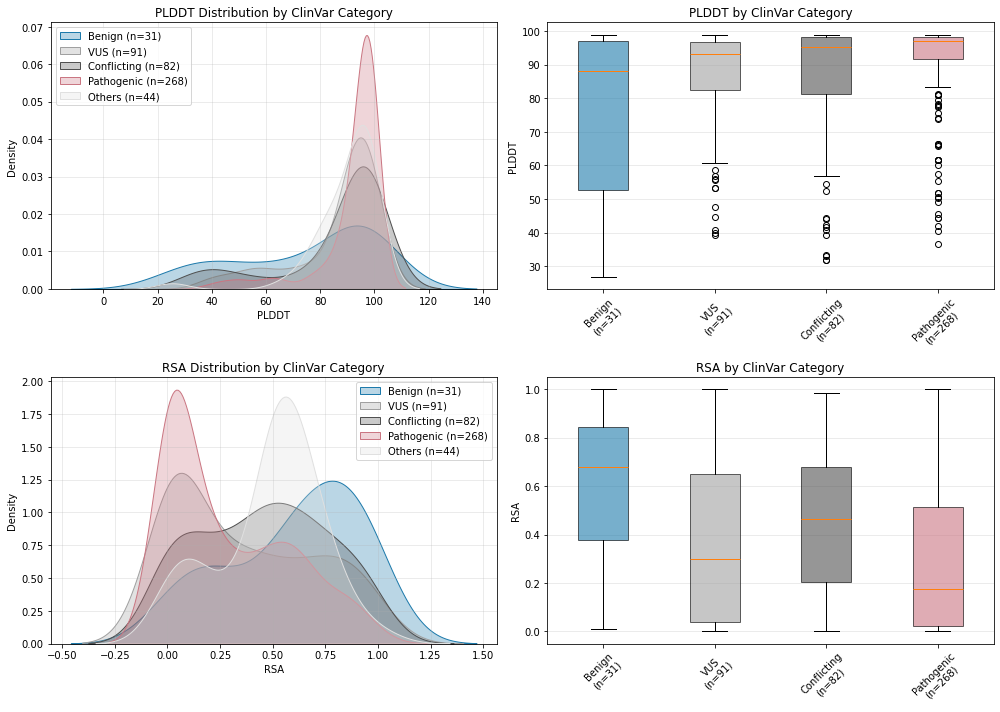

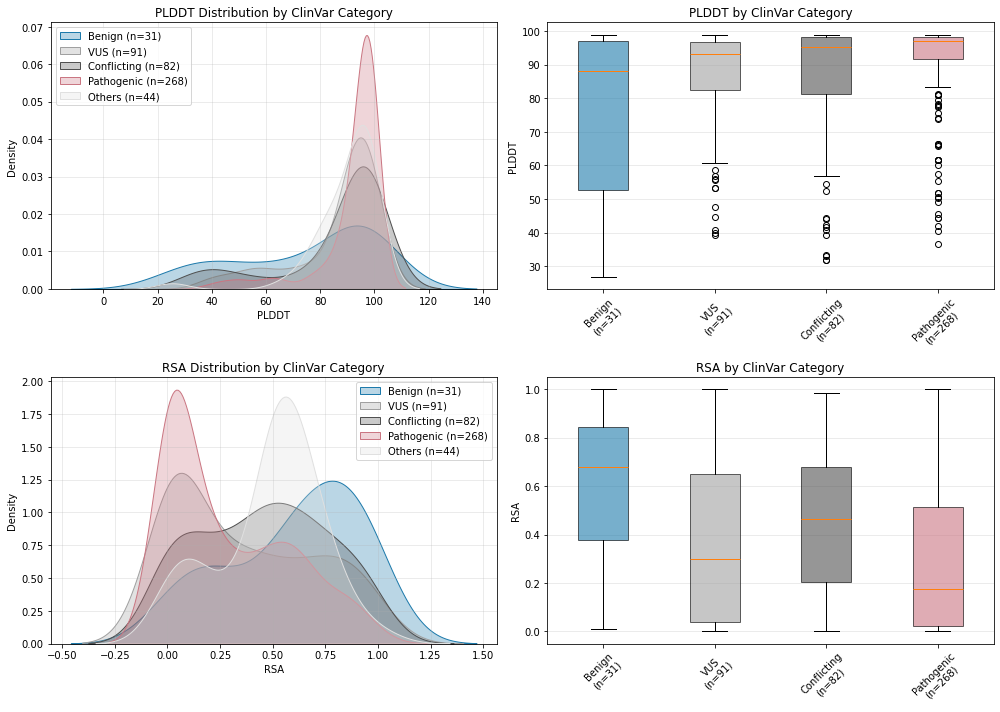

In [ ]:
# Plot pLDDT and RSA for main ClinVar categories
plot_structural_features_by_clinvar(
    orf_distances, 
    features=['plddt', 'rsa'],
    clinvar_col='clinvar_clnsig_clean'
)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_76677/3945754855.py:80: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_box.boxplot(plot_data, labels=plot_labels, patch_artist=True)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_76677/3945754855.py:80: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_box.boxplot(plot_data, labels=plot_labels, patch_artist=True)



PLDDT Statistics by ClinVar Category
Likely benign       : n=  23, mean=76.313, median=88.240, std=23.828
VUS                 : n=  91, mean=86.307, median=93.220, std=16.195
Conflicting         : n=  81, mean=84.824, median=95.040, std=20.516
Pathogenic          : n= 166, mean=90.420, median=96.235, std=13.825
Others              : n=  50, mean=89.847, median=95.795, std=12.893
Likely pathogenic   : n=  97, mean=93.818, median=97.620, std=9.638
Benign              : n=   8, mean=69.611, median=78.930, std=31.767

RSA Statistics by ClinVar Category
Likely benign       : n=  23, mean=0.545, median=0.560, std=0.319
VUS                 : n=  91, mean=0.363, median=0.297, std=0.333
Conflicting         : n=  81, mean=0.459, median=0.466, std=0.302
Pathogenic          : n= 166, mean=0.312, median=0.231, std=0.300
Others              : n=  50, mean=0.459, median=0.533, std=0.255
Likely pathogenic   : n=  97, mean=0.233, median=0.132, std=0.257
Benign              : n=   8, mean=0.748, median

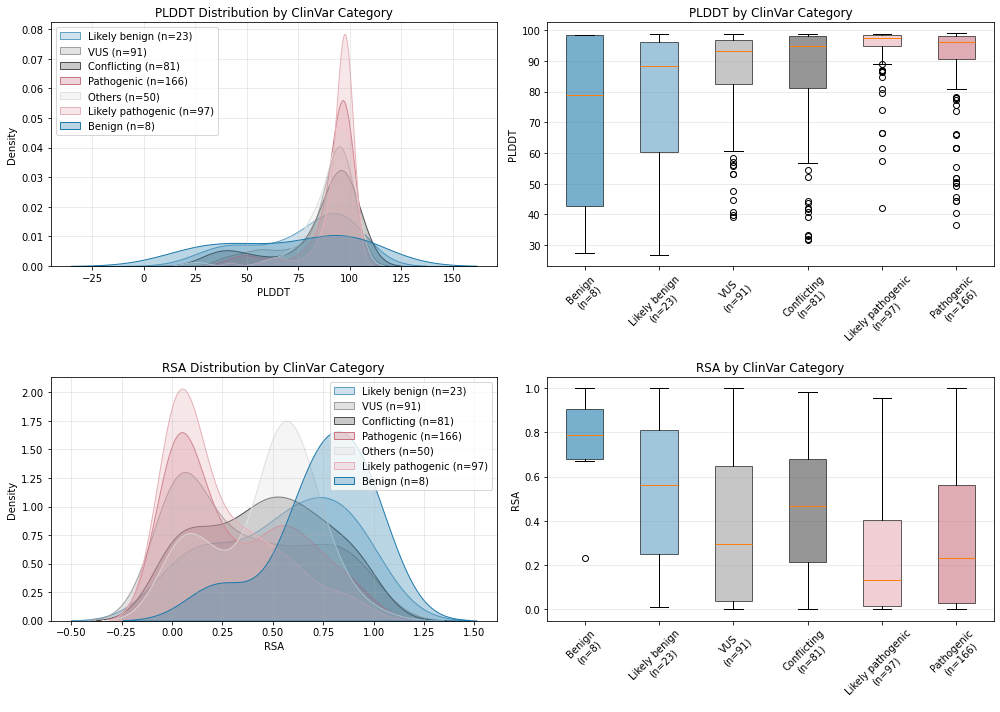

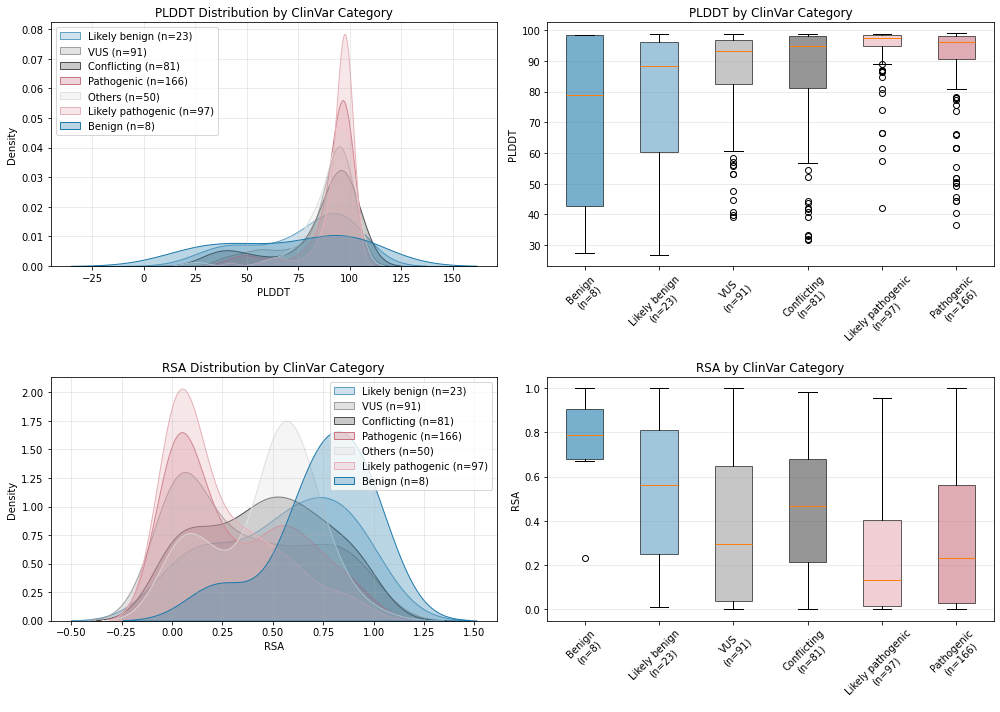

In [ ]:
# Plot using stricter ClinVar classification
plot_structural_features_by_clinvar(
    orf_distances, 
    features=['plddt', 'rsa'],
    clinvar_col='clinvar_clnsig_clean_pp_strict'
)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_76677/771649454.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_76677/771649454.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


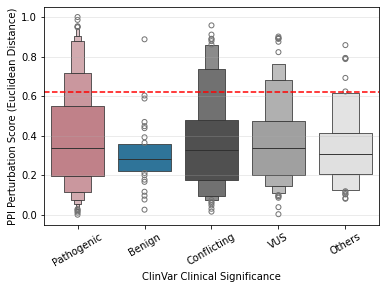

In [ ]:

order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

ax = sns.boxenplot(
    data=orf_distances,
    x="clinvar_clnsig_clean",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
ax.set_xlabel("ClinVar Clinical Significance")
plt.axhline(y=0.620, color='red', linestyle='--', label='LLR Threshold (0.620)')
plt.show()


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_76677/3443989829.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_76677/3443989829.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


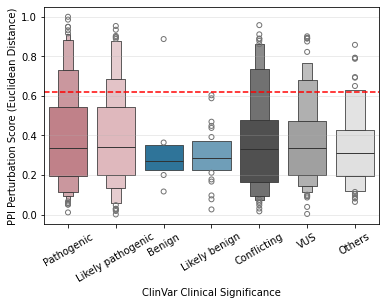

In [ ]:

order = ["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"]

ax = sns.boxenplot(
    data=orf_distances,
    x="clinvar_clnsig_clean_pp_strict",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
plt.axhline(y=0.620, color='red', linestyle='--', label='LLR Threshold (0.620)')
ax.set_xlabel("ClinVar Clinical Significance")
plt.show()


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_76677/3966634490.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_76677/3966634490.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


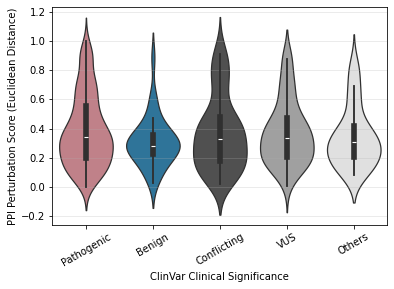

In [ ]:
order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

ax = sns.violinplot(
    data=orf_distances,
    x="clinvar_clnsig_clean",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
ax.set_xlabel("ClinVar Clinical Significance")
plt.show()


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_76677/3734749167.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_76677/3734749167.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


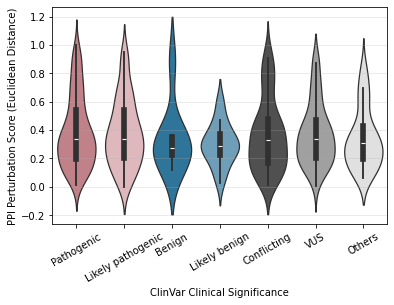

In [ ]:
order = ["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"]

ax = sns.violinplot(
    data=orf_distances,
    x="clinvar_clnsig_clean_pp_strict",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
ax.set_xlabel("ClinVar Clinical Significance")
plt.show()


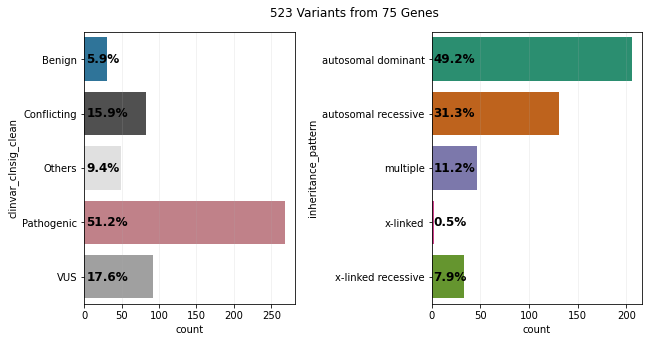

In [ ]:
orf_pd = orf_distances.to_pandas()

original_df = pl.DataFrame(orf_pd)

plot_df = orf_pd[orf_pd.clinvar_clnsig_clean.isin(['Pathogenic', 'Benign', 'Conflicting', 'VUS', 'Others'])]


scores_dedup_pl = pl.DataFrame(plot_df)


fig, axes = plt.subplots(1,2,figsize=(10,5))
plot_cat_count_perc(
    scores_dedup_pl,
    "clinvar_clnsig_clean",
    title="ClinVar",
    ax=axes[0],
    palette=palette_dict["clinvar_clnsig_clean"]
)
plot_df = plot_df[plot_df.inheritance_pattern.isin(['autosomal dominant', 'autosomal recessive', 'multiple', 'x-linked', 'x-linked recessive'])]

scores_dedup_pl = pl.DataFrame(plot_df)
plot_cat_count_perc(
    scores_dedup_pl,
    "inheritance_pattern",
    title="Inheritance",
    ax=axes[1],
)

plt.suptitle(f"{original_df.unique('gene_variant').shape[0]} Variants from {original_df.unique('symbol').shape[0]} Genes", y=.95)
plt.subplots_adjust(wspace=.65)
plt.show()

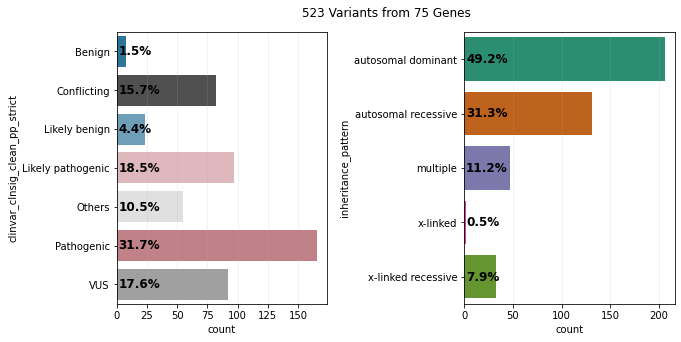

In [ ]:
orf_pd = orf_distances.to_pandas()

original_df = pl.DataFrame(orf_pd)

plot_df = orf_pd[orf_pd.clinvar_clnsig_clean_pp_strict.isin(["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"])]


scores_dedup_pl = pl.DataFrame(plot_df)


fig, axes = plt.subplots(1,2,figsize=(10,5))
plot_cat_count_perc(
    scores_dedup_pl,
    "clinvar_clnsig_clean_pp_strict",
    title="ClinVar",
    ax=axes[0],
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"]
)
plot_df = plot_df[plot_df.inheritance_pattern.isin(['autosomal dominant', 'autosomal recessive', 'multiple', 'x-linked', 'x-linked recessive'])]

scores_dedup_pl = pl.DataFrame(plot_df)
plot_cat_count_perc(
    scores_dedup_pl,
    "inheritance_pattern",
    title="Inheritance",
    ax=axes[1],
)

plt.suptitle(f"{original_df.unique('gene_variant').shape[0]} Variants from {original_df.unique('symbol').shape[0]} Genes", y=.95)
plt.subplots_adjust(wspace=.65)
plt.show()

clinvar_clnsig_clean,total_counts,hit_counts,hit_perc
str,u32,u32,f64
"""Benign""",31,1,3.225806
"""Conflicting""",83,15,18.072289
"""Others""",49,6,12.244898
"""Pathogenic""",268,51,19.029851
"""VUS""",92,14,15.217391


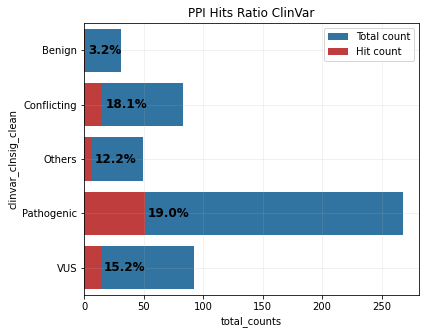

In [ ]:
scores_dedup_with_gene_variant = orf_distances.filter(
    pl.col("clinvar_clnsig_clean").is_in(['Pathogenic', 'Benign', 'Conflicting', 'VUS', 'Others']) #pl.col("Gene")!="BRCA1" #
)

plot_assay_hit_by_category(scores_dedup_with_gene_variant, "ppi_hit", "clinvar_clnsig_clean", f"PPI Hits Ratio ClinVar")

clinvar_clnsig_clean_pp_strict,total_counts,hit_counts,hit_perc
str,u32,u32,f64
"""Benign""",8,1,12.5
"""Conflicting""",82,15,18.292683
"""Likely benign""",23,0,0.0
"""Likely pathogenic""",97,17,17.525773
"""Others""",55,8,14.545455
"""Pathogenic""",166,32,19.277108
"""VUS""",92,14,15.217391


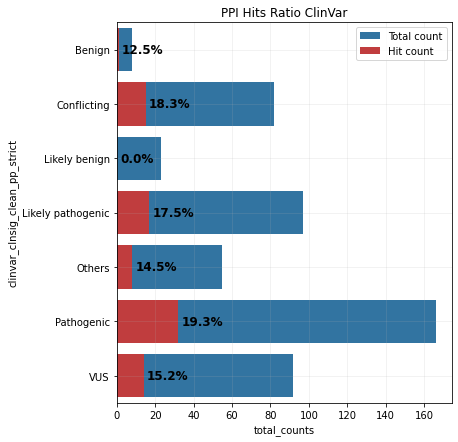

In [ ]:
scores_dedup_with_gene_variant = orf_distances.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"]) #pl.col("Gene")!="BRCA1" #
)

plot_assay_hit_by_category(scores_dedup_with_gene_variant, "ppi_hit", "clinvar_clnsig_clean_pp_strict", f"PPI Hits Ratio ClinVar")

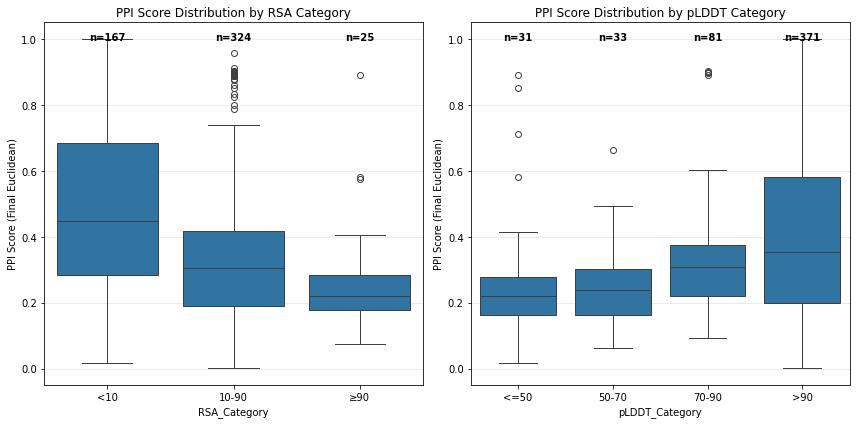

RSA Category Summary:
              count   mean  median    std
RSA_Category                             
<10             167  0.464   0.448  0.251
10-90           324  0.335   0.304  0.217
≥90              25  0.272   0.220  0.183

pLDDT Category Summary:
                count   mean  median    std
pLDDT_Category                             
<=50               31  0.278   0.220  0.214
50-70              33  0.253   0.239  0.132
70-90              81  0.329   0.307  0.175
>90               371  0.402   0.354  0.249


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_76677/1429374680.py:51: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rsa_summary = rsa_data.groupby('RSA_Category')['normalized_euclid_distance_normalized'].agg(['count', 'mean', 'median', 'std']).round(3)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_76677/1429374680.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  plddt_summary = plddt_data.groupby('pLDDT_Category')['normalized_euclid_distance_normalized'].agg(['count', 'mean', 'median', 'std']).round(3)


In [ ]:
# Set the proper order for both RSA and pLDDT categories
rsa_order = ['<10', '10-90', '≥90']
plddt_order = ["<=50", "50-70", "70-90", ">90"]

# First convert to pandas to set the categorical order, then back to polars
all_variants_df_ppi_pd = orf_distances.to_pandas()

# Set categorical order for both RSA and pLDDT
all_variants_df_ppi_pd['RSA_Category'] = pd.Categorical(
    all_variants_df_ppi_pd['RSA_Category'], 
    categories=rsa_order, 
    ordered=True
)
all_variants_df_ppi_pd['pLDDT_Category'] = pd.Categorical(
    all_variants_df_ppi_pd['pLDDT_Category'], 
    categories=plddt_order, 
    ordered=True
)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# RSA Category boxplot
rsa_data = all_variants_df_ppi_pd.dropna(subset=['RSA_Category', 'normalized_euclid_distance_normalized'])
sns.boxplot(data=rsa_data, x='RSA_Category', y='normalized_euclid_distance_normalized', ax=axes[0])
axes[0].set_title('PPI Score Distribution by RSA Category')
axes[0].set_ylabel('PPI Score (Final Euclidean)')
axes[0].grid(alpha=0.3, axis='y')

# Add sample sizes for RSA categories (using ordered categories)
for i, category in enumerate(rsa_order):
    n = len(rsa_data[rsa_data['RSA_Category'] == category])
    axes[0].text(i, axes[0].get_ylim()[1] * 0.95, f'n={n}', ha='center', fontweight='bold')

# pLDDT Category boxplot  
plddt_data = all_variants_df_ppi_pd.dropna(subset=['pLDDT_Category', 'normalized_euclid_distance_normalized'])
sns.boxplot(data=plddt_data, x='pLDDT_Category', y='normalized_euclid_distance_normalized', ax=axes[1])
axes[1].set_title('PPI Score Distribution by pLDDT Category')
axes[1].set_ylabel('PPI Score (Final Euclidean)')
axes[1].grid(alpha=0.3, axis='y')

# Add sample sizes for pLDDT categories
for i, category in enumerate(plddt_order):
    n = len(plddt_data[plddt_data['pLDDT_Category'] == category])
    axes[1].text(i, axes[1].get_ylim()[1] * 0.95, f'n={n}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("RSA Category Summary:")
rsa_summary = rsa_data.groupby('RSA_Category')['normalized_euclid_distance_normalized'].agg(['count', 'mean', 'median', 'std']).round(3)
print(rsa_summary)

print("\npLDDT Category Summary:")
plddt_summary = plddt_data.groupby('pLDDT_Category')['normalized_euclid_distance_normalized'].agg(['count', 'mean', 'median', 'std']).round(3)
print(plddt_summary)

pLDDT_Category,total_counts,hit_counts,hit_perc
cat,u32,u32,f64
"""50-70""",33,1,3.030303
"""70-90""",81,4,4.938272
"""<=50""",31,3,9.677419
""">90""",371,78,21.024259


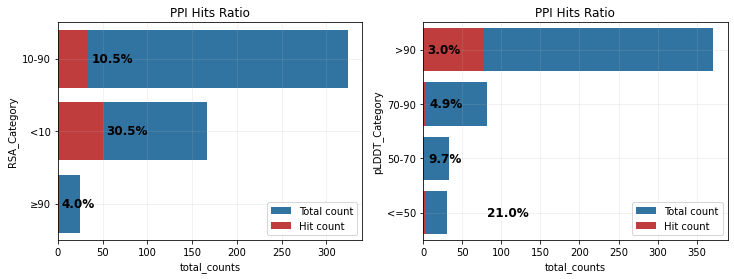

In [ ]:
# Set the proper order for pLDDT categories
plddt_order = ["<=50", "50-70", "70-90", ">90"]

# First convert to pandas to set the categorical order, then back to polars
all_variants_df_ppi_pd = orf_distances.to_pandas()
all_variants_df_ppi_pd['pLDDT_Category'] = pd.Categorical(
    all_variants_df_ppi_pd['pLDDT_Category'], 
    categories=plddt_order, 
    ordered=True
)
all_variants_df_ppi_pl = pl.from_pandas(all_variants_df_ppi_pd)

fig, axes = plt.subplots(1,2,figsize=(12,4))
plot_assay_hit_by_category(all_variants_df_ppi_pl.drop_nulls(subset='RSA_Category'), "ppi_hit", "RSA_Category", f"PPI Hits Ratio", ax=axes[0])
plot_assay_hit_by_category(all_variants_df_ppi_pl.drop_nulls(subset='pLDDT_Category'), "ppi_hit", "pLDDT_Category", f"PPI Hits Ratio", ax=axes[1])